# PHÂN TÍCH DỮ LIỆU CHO THUÊ CĂN HỘ
- Họ Tên: Đoàn Minh Huy
- MSSV: 24700701

## 1. Giới thiệu đề tài
### 1.1. Bối cảnh và lý do chọn đề tài
Dữ liệu căn hộ cho thuê chứa nhiều thông tin như giá thuê, số phòng ngủ, số phòng tắm và vị trí. Việc phân tích dữ liệu giúp khám phá đặc điểm các căn hộ và mối quan hệ giữa giá thuê và những thuộc tính liên quan

Đề tài sử dụng bộ dữ liệu Apartments for Rent Classified ARC từ UCI Machine Learning Reposity nhằm thực hành quy trình phân tích dữ liệu bằng ipynb, bao gồm khám phá, làm sạch, thống kê, trực quan hóa và áp dụng các thuật toán.

### 1.2. Mục tiêu
- Tìm hiểu cấu trúc và các thuộc tính của bộ dữ liệu căn hộ cho thuê
- Kiểm tra, làm sạch và xử lý các vấn đề trong dữ liệu
- Thực hiện thống kê mô tả và trực quan hóa để tìm hiểu đặc điểm, sự phân bố và mối quan hệ giữa các thuộc tính
- Áp dụng các phương pháp thống kê và thuật toán cơ bản đã học
- Nhận xét, đánh giá kết quả phân tích và rút ra kết luận từ dữ liệu

## 2. Tổng quan và khám phá dữ liệu
### 2.1. Giới thiệu bộ dữ liệu Apartment for Rent
Bộ dữ liệu Apartment for Rent hay chính xác hơn là Apartment for Rent Classified là một bộ dữ liệu và các tin cho thuê nhà và căn hộ tại Mỹ. Bộ dữ liệu trên được em lấy từ UCI, một trang web có mã nguồn dataset mở, được đóng góp vào 25/12/2019. Bộ dữ liệu có 22 thuộc tính và khoảng 100000 bản ghi.

Với AFRC, em tập trung tìm hiểu đăc điểm của các căn hộ cho thuê, phân tích sự phân bố giá thuê và mối quan hệ giữa giá thuê với các thuộc tính liên quan. 

Nguồn: [AFRC Dataset](https://archive.ics.uci.edu/dataset/555/apartment+for+rent+classified)

### 2.2. Mô tả cấu trúc dữ liệu
Dataset gồm 22 thuộc tính, chia thành bốn nhóm chính.
1. Thông tin đăng ký: id, category, title, body, source, time
2. Thông tin căn hộ: square_feet, bedrooms, bathrooms, amenities, pets_allowed, has_photo
3. Thông tin giá thuê: price, price_display, price_type, currency, fee
4. Thông tin vị trí: address, cityname, state, latitude, longtitude

Các thuộc tính có cả kiểu dữ liệu số và chuỗi. Price sẽ là thuộc tính chính để tìm hiểu mối quan hệ giữa giá thuê với diện tích, số phòng, vị trí,...

### 2.3. Sơ đồ thực thể – liên kết (ERD)
Với dataset AFRC, em xây dựng ERD rồi 3 thực thể
1. THONGTINCANHO: Lưu thông tin về căn hộ
2. DIADIEM: Lưu thông tin thành phố hoặc địa điểm của căn hộ
3. NGUONTIN: Lưu thông tin nguồn đăng tin của căn hộ

Thực thể được liên kết thông qua PK và FK với hai mỗi quan hệ 1-n

![ERD của AFRC](../image/erdAFRC.png.png)

Giải thích:
Quan hệ 1: DIADIEM - THONGTINCANHO 1 - 0..n
- Một địa điểm có thể có nhiều tin đăng cho thuê
- Mỗi tin đăng thuộc một địa điểm trong mô hình.
- Liên kết bằng location_id

Quan hệ 2:
- Mọi nguồn đăng tin có thể cung cấp nhiều tin được đăng
- Mỗi tin đăng được gắn với một nguồn
- Liên kết bằng source_id

Em có bổ sung thêm 3 thuộc tính là listing_key, location_key và source_id để làm thuộc tính định danh và chỉ tồn tại trên ERD, không có sẵn trong dataset gốc.

### 2.4. Nạp dữ liệu vào Pandas
Sử dụng thư viện để đọc dataset từ file CSV và hiển thị vài dòng dữ liệu đầu để kiểm tra dữ liệu đã được nạp.

In [52]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/apartments_for_rent_classified_100K.csv",
    sep=";",
    encoding="cp1252",
    low_memory=False
)

display(df.head())

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668640009,housing/rent/apartment,One BR 507 & 509 Esplanade,"This unit is located at 507 & 509 Esplanade, R...",NaN,1.0,1.0,USD,No,Thumbnail,...,"$2,195",Monthly,542,507 509 Esplanade,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,5668639818,housing/rent/apartment,Three BR 146 Lochview Drive,"This unit is located at 146 Lochview Drive, Ne...",NaN,1.5,3.0,USD,No,Thumbnail,...,"$1,250",Monthly,1500,146 Lochview Dr,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,5668639686,housing/rent/apartment,Three BR 3101 Morningside Drive,This unit is located at 3101 Morningside Drive...,NaN,2.0,3.0,USD,No,Thumbnail,...,"$1,395",Monthly,1650,3101 Morningside Dr,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332
3,5668639659,housing/rent/apartment,Two BR 209 Aegean Way,"This unit is located at 209 Aegean Way, Vacavi...",NaN,1.0,2.0,USD,No,Thumbnail,...,"$1,600",Monthly,820,209 Aegean Way,Vacaville,CA,38.3622,-121.9712,RentLingo,1577360330
4,5668639374,housing/rent/apartment,One BR 4805 Marquette NE,"This unit is located at 4805 Marquette NE, Alb...",NaN,1.0,1.0,USD,No,Thumbnail,...,$975,Monthly,624,4805 Marquette NE,Albuquerque,NM,35.1038,-106.6110,RentLingo,1577360308


**Nhận xét**: Dữ liệu đã được đẩy vào DataFrame thành công. Kêt quả hiển thị 5 dòng đầu tiên với 22 thuộc tính bao gồm thông tin đăng, giá thuê,... .

### 2.5. Khám phá thông tin tổng quan
Sau khi đã có dữ liệu, kiểm tra kích thước, tên thuộc tính, kiểu dữ liệu và các thông tin thống kê cơ bản của dữ liệu.

#### Kiểm tra kích thước và tên thuộc tính

In [53]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("Danh sách thuộc tính:")
print(df.columns.tolist())

Số dòng: 99492
Số cột: 22
Danh sách thuộc tính:
['id', 'category', 'title', 'body', 'amenities', 'bathrooms', 'bedrooms', 'currency', 'fee', 'has_photo', 'pets_allowed', 'price', 'price_display', 'price_type', 'square_feet', 'address', 'cityname', 'state', 'latitude', 'longitude', 'source', 'time']


#### Xem cấu trúc và kiểu dữ liệu

In [54]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             99492 non-null  int64  
 1   category       99492 non-null  str    
 2   title          99492 non-null  str    
 3   body           99492 non-null  str    
 4   amenities      83448 non-null  str    
 5   bathrooms      99429 non-null  float64
 6   bedrooms       99368 non-null  float64
 7   currency       99492 non-null  str    
 8   fee            99492 non-null  str    
 9   has_photo      99492 non-null  str    
 10  pets_allowed   39068 non-null  str    
 11  price          99491 non-null  float64
 12  price_display  99491 non-null  str    
 13  price_type     99492 non-null  str    
 14  square_feet    99492 non-null  int64  
 15  address        7943 non-null   str    
 16  cityname       99190 non-null  str    
 17  state          99190 non-null  str    
 18  latitude       99

#### Thống kê cơ bản của dữ liệu

In [55]:
display(df.describe())

,id,bathrooms,bedrooms,price,square_feet,latitude,longitude,time
count,9.949200e+04,99429.000000,99368.000000,99491.000000,99492.000000,99467.000000,99467.000000,9.949200e+04
mean,5.358321e+09,1.445323,1.728212,1527.057281,956.430688,36.947988,-91.568656,1.559665e+09
std,1.847404e+08,0.547021,0.749200,904.245882,417.571522,4.599461,15.817168,1.105077e+07
min,5.121046e+09,1.000000,0.000000,100.000000,101.000000,19.573800,-159.369800,1.544174e+09
25%,5.197950e+09,1.000000,1.000000,1013.000000,729.000000,33.746500,-104.791900,1.550832e+09
50%,5.508673e+09,1.000000,2.000000,1350.000000,900.000000,37.228200,-84.562300,1.568745e+09
75%,5.509007e+09,2.000000,2.000000,1795.000000,1115.000000,39.953000,-77.608200,1.568767e+09
max,5.669439e+09,9.000000,9.000000,52500.000000,50000.000000,64.833200,-68.778800,1.577391e+09


**Nhận xét:**
- Bộ dữ liệu có 99492 bản ghi và 22 thuộc tính, gồm 5 thuộc tính float64, 3 thuộc tính int64 và 14 thuộc tính str
- Một số thuộc tính còn giá trị thiếu như amenities, pets_allowed, address, bathrooms, bedrooms, và vị trí, trong đó address và pets_allowed có số lượng giá trị thiếu khá lớn.
- Giá thuê (price) trung bình khoảng 1.527 USD, trung vị là 1.350 USD. Giá thuê thấp nhất là 100 USD và cao nhất là 52.500 USD.
- Diện tích (square_feet) trung bình khoảng 956 ft^2, trung vị là 900 ft^2 . Số phòng ngủ trung bình khoảng 1,73 và số phòng tắm trung bình khoảng 1,45.
- Từ ở phần thống kê cơ bản có thể thấy có một sự chênh lệch lớn của tiền thuê giữa căn hộ có diện tích lớn và nhỏ

### 2.6. Truy vấn dữ liệu có điều kiện
Sử dụng các lệnh để lọc và sắp xếp dữ liệu theo một số điều kiện nhằm xem thông tin các tin đăng thỏa mãn yêu cầu.

#### Lọc theo một điều kiện
Hiển thị các tin đăng có 2 phòng ngủ.

In [56]:
df_2_bedrooms = df.loc[
    df["bedrooms"] == 2,
    ["id", "cityname", "state", "bedrooms", "square_feet", "price"]
]

print("Số tin đăng có 2 phòng ngủ:", len(df_2_bedrooms))
display(df_2_bedrooms.head(10))

Số tin đăng có 2 phòng ngủ: 45975


,id,cityname,state,bedrooms,square_feet,price
3,5668639659,Vacaville,CA,2.0,820,1600.0
5,5668639368,Albuquerque,NM,2.0,965,1250.0
6,5668638765,Hampton,VA,2.0,1120,1600.0
7,5668638578,Lakewood,CO,2.0,947,1300.0
8,5668638476,Charleston,WV,2.0,600,795.0
9,5668638122,Chatsworth,CA,2.0,1005,2150.0
11,5668637998,Marblehead,MA,2.0,3077,3195.0
12,5668637809,Washington,DC,2.0,896,2395.0
15,5668636381,Kirkland,WA,2.0,872,2000.0
19,5668633909,Portland,OR,2.0,435,1250.0


#### Lọc thoe nhiều điều kiện
Tìm các tin đăng có giá thuê từ 1000 USD đến 2000 USD trên một tháng

In [57]:
df_price_range = df.loc[
    (df["price"] >= 1000) &
    (df["price"] <= 2000) &
    (df["currency"] == "USD") &
    (df["price_type"] == "Monthly"),
    ["id", "cityname", "state", "price", "currency",
     "price_type", "square_feet"]
]

print("Số tin đăng thỏa điều kiện:", len(df_price_range))
display(df_price_range.head(10))

Số tin đăng thỏa điều kiện: 57968


,id,cityname,state,price,currency,price_type,square_feet
1,5668639818,Newport News,VA,1250.0,USD,Monthly,1500
2,5668639686,Raleigh,NC,1395.0,USD,Monthly,1650
3,5668639659,Vacaville,CA,1600.0,USD,Monthly,820
5,5668639368,Albuquerque,NM,1250.0,USD,Monthly,965
6,5668638765,Hampton,VA,1600.0,USD,Monthly,1120
7,5668638578,Lakewood,CO,1300.0,USD,Monthly,947
10,5668638015,Alpharetta,GA,1795.0,USD,Monthly,1522
15,5668636381,Kirkland,WA,2000.0,USD,Monthly,872
17,5668635018,Villa Park,IL,1045.0,USD,Monthly,700
18,5668634255,Oxford,MS,1800.0,USD,Monthly,1500


#### Sắp xếp dữ liệu
Sắp xếp các tin đã lọc theo giá thuê bên trên theo giảm dần

In [58]:
df_sorted = df_price_range.sort_values(
    by="price",
    ascending=False
)

display(df_sorted.head(10))

,id,cityname,state,price,currency,price_type,square_feet
99328,5122057036,Suwanee,GA,2000.0,USD,Monthly,2394
37197,5508842276,Braintree,MA,2000.0,USD,Monthly,1000
72,5668639731,Kent,WA,2000.0,USD,Monthly,1220
15,5668636381,Kirkland,WA,2000.0,USD,Monthly,872
58594,5198520256,Irvine,CA,2000.0,USD,Monthly,737
58589,5198521971,Naples,FL,2000.0,USD,Monthly,768
15187,5508715410,Harrison,NJ,2000.0,USD,Monthly,785
58564,5198531516,Beverly,MA,2000.0,USD,Monthly,716
15149,5508741312,Boston,MA,2000.0,USD,Monthly,1000
15137,5508747893,Boston,MA,2000.0,USD,Monthly,1000


**Nhận xét:**
1. Có 45975 tin có 2 phòng ngủ. Trong 10 dòng được hiển thị, các căn hộ có diện tích và giá thuê khác nhau tùy theo từng tin đăng
2. Có 57968 tin thỏa mãn giá thuê từ 1000 đến 2000 USD một thnags. CHo thấy nhiều tin đăng nằm trong khoảng giá được chọn
3. Sau khi sắp xếp giá thuê giảm dần, 10 dòng đầu tiên có giá thuê 2000 USD. Tuy có cùng mức giá hưng cso thể thấy diện tích và vị trí là khác nhau

### 2.7. Sắp xếp và lọc dữ liệu
Tiếp tục lọc các tin đăng theo vị trí và đặc điểm căn hộ, sau đó sắp xếp kết quả theo nhiều thuộc tính để dễ quan sát và so sánh dữ liệu

#### Lọc theo vị trí và số phòng ngủ

In [59]:
df_ca = df.loc[
    (df["state"] == "CA") &
    (df["bedrooms"] >= 2),
    ["id", "cityname", "state", "bedrooms", "square_feet", "price"]
]

print("Số tin đăng thỏa điều kiện:", len(df_ca))
display(df_ca.head(10))


Số tin đăng thỏa điều kiện: 5750


,id,cityname,state,bedrooms,square_feet,price
3,5668639659,Vacaville,CA,2.0,820,1600.0
9,5668638122,Chatsworth,CA,2.0,1005,2150.0
28,5668630836,Ladera Ranch,CA,3.0,1525,3250.0
39,5668627095,San Jose,CA,3.0,1739,3990.0
41,5668627015,Oakland,CA,2.0,860,2550.0
42,5668626906,Mission Viejo,CA,4.0,3350,4950.0
43,5668626824,Berkeley,CA,2.0,1200,4950.0
46,5668625042,Sherman Oaks,CA,2.0,1391,2548.0
61,5668615317,Sacramento,CA,2.0,572,1385.0
106,5668627070,Hawthorne,CA,2.0,1070,2200.0


#### Sắp xếp theo nhiều thuộc tính

In [60]:
df_ca_sorted = df_ca.sort_values(
    by=["bedrooms", "square_feet"],
    ascending=[True, False]
)

display(df_ca_sorted.head(10))

,id,cityname,state,bedrooms,square_feet,price
32210,5509261541,Pasadena,CA,2.0,2535,5750.0
17162,5508880768,Los Angeles,CA,2.0,2372,6400.0
39472,5508925329,Beverly Hills,CA,2.0,2330,11000.0
20827,5509043710,Santa Monica,CA,2.0,2328,5950.0
5298,5664598216,Encinitas,CA,2.0,2283,5350.0
33700,5508681886,Los Angeles,CA,2.0,2274,7920.0
16174,5508798859,Los Angeles,CA,2.0,2248,6500.0
40698,5508905079,West Hollywood,CA,2.0,2246,11500.0
77742,5197985405,Indio,CA,2.0,2147,2250.0
75580,5198008022,Beaumont,CA,2.0,2127,1800.0


**Nhận xét:**
1. Có 5750 tin tại bang CA có từ 2 phòng ngủ trở lên. Trong 10 dòng đầu tiên, số phòng ngủ, diện tích, giá thuê có sự khác nhau tùy theo căn hộ
2. Sau khi sắp xếp theo số phòng ngủ tăng dần, diện tích giảm dần, 10 dòng đầu đều có 2 phòng ngủm diện tích từ 2100 đến 2550 ft^2. Giá thuê của các căn hộ này cũng có sự chênh lệch, từ 1800 đến 11500 USD.

## 3. Tiền xử lý và làm sạch dữ liệu
### 3.1. Kiểm tra dữ liệu thiếu
Sử dụng các lệnh để kiểm tra số lượng và tỉ lệ giá trị thiếu ở từng thuộc tính. Trực quan hóa bằng biểu đồ để xác định những thuộc tính có nhiều dữ liệu thiếu

#### Kiểm tra số lượng và tỷ lệ dữ liệu thiếu

In [61]:

missing_count = df.isnull().sum()

missing_percent = (missing_count / len(df) * 100).round(2)

df_missing = pd.DataFrame({
    "Số lượng thiếu": missing_count,
    "Tỷ lệ thiếu (%)": missing_percent
})

df_missing = df_missing.sort_values(
    by="Số lượng thiếu",
    ascending=False
)

display(df_missing)

print("Số thuộc tính có dữ liệu thiếu:",
      (missing_count > 0).sum())


,Số lượng thiếu,Tỷ lệ thiếu (%)
address,91549,92.02
pets_allowed,60424,60.73
amenities,16044,16.13
cityname,302,0.30
state,302,0.30
bedrooms,124,0.12
bathrooms,63,0.06
latitude,25,0.03
longitude,25,0.03
price,1,0.00


Số thuộc tính có dữ liệu thiếu: 11


**Nhận xét:**
- Dữ liệu có 11/22 thuộc tính xuất hiện giá trị thiếu, trong khi 11 thuộc tính còn lại không thiếu
- Trong đó address có tý lệ cao nhất với 92,02%, theo sau là pets_allowed 60,73% và amenities với 16,13%
- Một số thuộc tính khác như cityname, state, bedrooms, bathrooms, latitude, longitude, price và price_display có thiếu, nhưng tỷ lệ rất thấp, dưới 1%

Nhìn chung, dữ liệu thiếu có sự chênh lệch khá lớn về tỷ lệ thiếu giữu các thuộc tính. 

### 3.2. Trực quan hóa dữ liệu thiếu


#### Biểu đồ cột ngang tỷ lệ dữ liệu thiếu

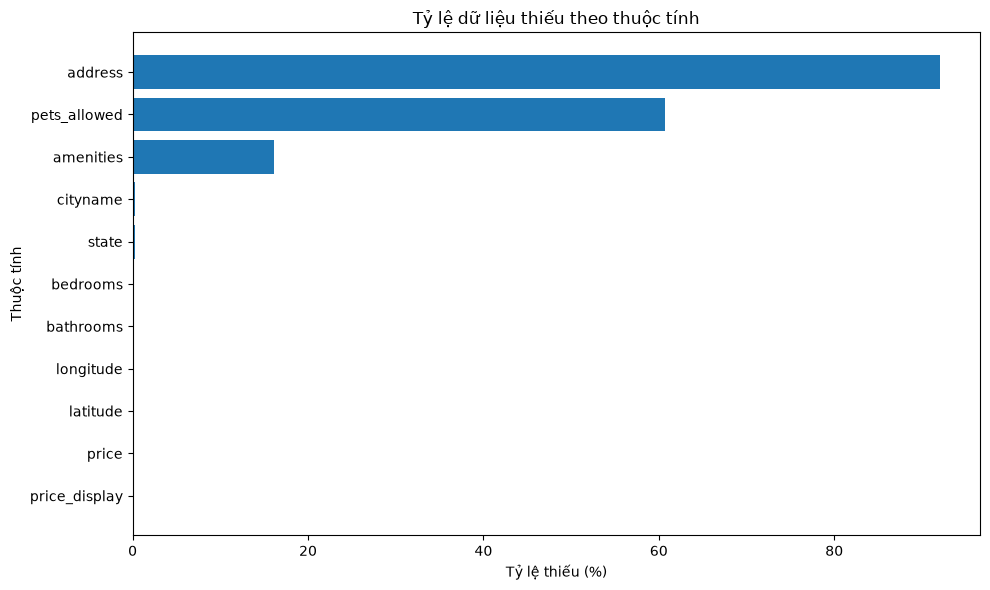

In [62]:
import matplotlib.pyplot as plt

missing_chart = df_missing[df_missing["Số lượng thiếu"] > 0]

missing_chart = missing_chart.sort_values(
    by="Tỷ lệ thiếu (%)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    missing_chart.index,
    missing_chart["Tỷ lệ thiếu (%)"]
)

plt.title("Tỷ lệ dữ liệu thiếu theo thuộc tính")
plt.xlabel("Tỷ lệ thiếu (%)")
plt.ylabel("Thuộc tính")

plt.tight_layout()
plt.show()


#### Biểu đồ heatmap dữ liệu thiếu

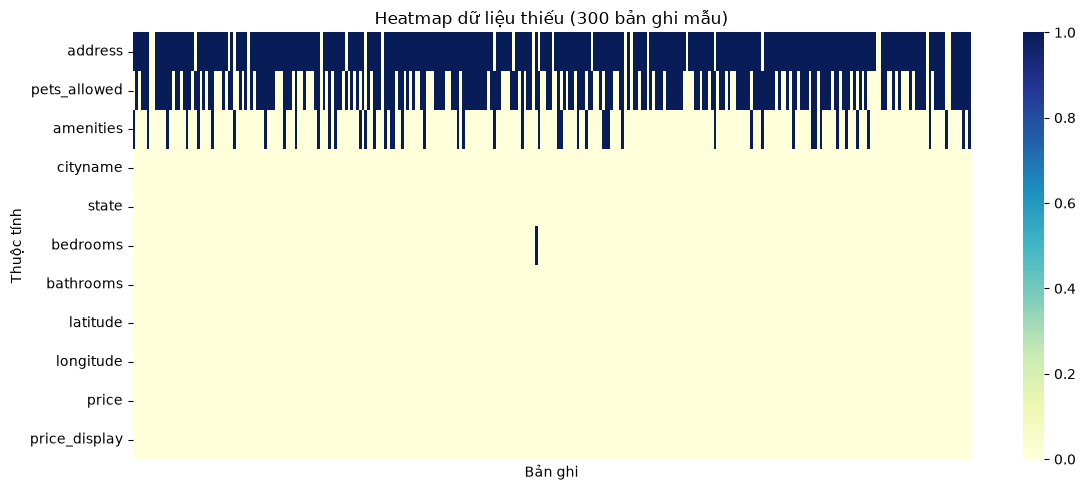

In [63]:

import seaborn as sns
import matplotlib.pyplot as plt

missing_cols = df_missing[
    df_missing["Số lượng thiếu"] > 0
].index

df_missing_sample = df[missing_cols].sample(
    n=300,
    random_state=42
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    df_missing_sample.isnull().T,
    cmap="YlGnBu",
    cbar=True,
    xticklabels=False
)

plt.title("Heatmap dữ liệu thiếu (300 bản ghi mẫu)")
plt.xlabel("Bản ghi")
plt.ylabel("Thuộc tính")

plt.tight_layout()
plt.show()


**Nhận xét**
1. Biểu đồ cột ngang: Dữ liệu thiếu tập trung chủ yếu ở address với 92,02%, pets_allowed 60,73% và amenities là 16,13%. Các thuộc tính còn lại không đáng kể với dưới 1%
2. Biểu đồ heatmap: Chọn 300 bản ghi, các ô màu xanh đậm thể hiện giá trị thiếu, xuất hiện nhiều nhất ở address và pets_allowed, tiếp theo là amenities. Các thuộc tính còn lại hầu như có đầy đủ dữ liệu
- Cả hai biểu đồ cho thấy dữ liệu thiếu có phân bố không đồng đều giữa các thuộc tính.

### 3.3. Kiểm tra dữ liệu trùng lặp
Dùng các hàm để kiểm tra các bản ghi trùng lặp trong dữu liệu, bao gồm trùng lặp toàn bộ dòng dữ liệu và trùng id.

#### Kiểm tra dữ liệu trùng lặp

In [64]:
duplicate_rows = df.duplicated().sum()

print("Số bản ghi trùng hoàn toàn:", duplicate_rows)

display(df[df.duplicated(keep=False)].head(10))

Số bản ghi trùng hoàn toàn: 84


,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
41914,5508806580,housing/rent/apartment,"Las Vegas, prime location Two BR, Apartment. P...",Live in the middle of it all! South is a pet f...,"Gym,Parking,Pool",2.0,2.0,USD,No,Yes,...,"$1,335",Monthly,1084,NaN,Las Vegas,NV,36.1536,-115.1965,RentDigs.com,1568754086
41915,5508806428,housing/rent/apartment,Northglenn Value. Pet OK!,"Square footage: 738 square ft, unit number: 06...","Gym,Parking,Pool,Storage",1.0,1.0,USD,No,Yes,...,"$1,331",Monthly,738,NaN,Northglenn,CO,39.8999,-104.9442,RentDigs.com,1568754072
41916,5508806391,housing/rent/apartment,Apartment in move in condition in District Hei...,Capital Courts has something for everyone. Loc...,"AC,Parking,Playground,Pool",1.5,3.0,USD,No,Yes,...,"$1,320",Monthly,943,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754069
41917,5508806299,housing/rent/apartment,"District Heights, prime location Two BR, Apart...",Income Requirement: Must have 2. 5x the rent i...,Parking,1.0,2.0,USD,No,Yes,...,"$1,349",Monthly,931,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754061
41918,5508806233,housing/rent/apartment,"Spacious One BR, One BA","Square footage: 680 sq-ft, unit number: 122. P...","Basketball,Gym,Patio/Deck,Playground,Pool",1.0,1.0,USD,No,Yes,...,"$1,260",Monthly,680,NaN,Denver,CO,39.8999,-104.9442,RentDigs.com,1568754056
41919,5508806180,housing/rent/apartment,Beautiful Thornton Apartment for rent,"Square footage: 827 sq-ft, unit number: 2034. ...","AC,Basketball,Clubhouse,Dishwasher,Fireplace,G...",1.0,1.0,USD,No,Yes,...,"$1,203",Monthly,827,NaN,Thornton,CO,39.8999,-104.9442,RentDigs.com,1568754052
41920,5508806119,housing/rent/apartment,"Bright District Heights, One BR, One BA for re...",Thanks for your interest in Rochelle Hall Apar...,Parking,1.0,1.0,USD,No,No,...,$950,Monthly,523,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754048
41921,5508806034,housing/rent/apartment,Los Angeles - 2bd/Two BA 966sqft Apartment for...,"Welcome to Cole, a newly constructed Wiseman c...",Gym,2.0,2.0,USD,No,Yes,...,"$3,095",Monthly,966,NaN,Los Angeles,CA,34.0911,-118.3430,RentDigs.com,1568754041
41922,5508805994,housing/rent/apartment,"$3,850/mo - must see to believe.","Welcome to Cole, a newly constructed Wiseman c...",Gym,3.0,3.0,USD,No,Yes,...,"$3,850",Monthly,1318,NaN,Los Angeles,CA,34.0911,-118.3430,RentDigs.com,1568754037
41923,5508805990,housing/rent/apartment,Apartment \ Two BA - ready to move in. Pet OK!,"Square footage: 1093 sq. feet, unit number: 13...","AC,Cable or Satellite,Clubhouse,Dishwasher,Fir...",2.0,2.0,USD,No,Yes,...,"$1,620",Monthly,1093,NaN,Denver,CO,39.8999,-104.9442,RentDigs.com,1568754037


#### Kiểm tra trùng id đăng

In [65]:

duplicate_ids = df["id"].duplicated().sum()

print("Số trường hợp ID trùng:", duplicate_ids)

df_duplicate_ids = df[
    df["id"].duplicated(keep=False)
].sort_values(by="id")

print(
    "ID trùng nhưng nội dung khác:",
    (df["id"].duplicated() & ~df.duplicated()).sum()
)

display(
    df_duplicate_ids[
        ["id", "title", "price", "square_feet", "cityname", "state"]
    ].head(10)
)


Số trường hợp ID trùng: 84
ID trùng nhưng nội dung khác: 0


,id,title,price,square_feet,cityname,state
79465,5195387513,Townhome like Duplex,2450.0,820,Lemon Grove,CA
83210,5195387513,Townhome like Duplex,2450.0,820,Lemon Grove,CA
83209,5197678700,This Apartment is a must see!,1489.0,983,Memphis,TN
79464,5197678700,This Apartment is a must see!,1489.0,983,Memphis,TN
79463,5197682059,"Spacious One BR, One BA",832.0,660,Olathe,KS
83208,5197682059,"Spacious One BR, One BA",832.0,660,Olathe,KS
83247,5197828778,"Two BA - $1,862/mo - Apartment - in a great ar...",1862.0,1261,Tempe,AZ
79502,5197828778,"Two BA - $1,862/mo - Apartment - in a great ar...",1862.0,1261,Tempe,AZ
79501,5197828852,The Best of the Best in the City of Tempe! Sav...,1877.0,1261,Tempe,AZ
83246,5197828852,The Best of the Best in the City of Tempe! Sav...,1877.0,1261,Tempe,AZ


**Nhận xét:**
1. Phát hiện 84 dòng trùng hoản toàn trên tất cả 22 thuộc tính của dataset
2. Có 84 dòng có id đăng trùng lặp. Từ bảng cho thấy những thông tin đăng có cùng id cugx có thông tin giống nhau về tiêu đề, giá thuê và diện tích và vị trí

### 3.4. Kiểm tra kiểu dữ liệu và định dạng
Kiểm tra kiểu dữ liệu và các giá trị của một số thuộc tính như giá thuê, đơn vị tiền, loại tin, thời gian để xác định những vấn đề về định dạng trước khi làm sạch dữ liệu

#### Kiểm tra định dạng và giá trị phân loại

In [66]:

check_columns = [
    "price", "price_display", "bedrooms",
    "bathrooms", "currency", "price_type", "time"
]

print("Kiểu dữ liệu:")
print(df[check_columns].dtypes)

display(
    df[["price", "price_display", "currency", "price_type"]].head(10)
)

print("\nĐơn vị tiền tệ:")
print(df["currency"].value_counts(dropna=False))

print("\nKỳ thanh toán:")
print(df["price_type"].value_counts(dropna=False))

print("\nLoại tin đăng:")
print(df["category"].value_counts(dropna=False))

print("\nTrạng thái hình ảnh:")
print(df["has_photo"].value_counts(dropna=False))


Kiểu dữ liệu:
price            float64
price_display        str
bedrooms         float64
bathrooms        float64
currency             str
price_type           str
time               int64
dtype: object


,price,price_display,currency,price_type
0,2195.0,"$2,195",USD,Monthly
1,1250.0,"$1,250",USD,Monthly
2,1395.0,"$1,395",USD,Monthly
3,1600.0,"$1,600",USD,Monthly
4,975.0,$975,USD,Monthly
5,1250.0,"$1,250",USD,Monthly
6,1600.0,"$1,600",USD,Monthly
7,1300.0,"$1,300",USD,Monthly
8,795.0,$795,USD,Monthly
9,2150.0,"$2,150",USD,Monthly



Đơn vị tiền tệ:
currency
USD    99492
Name: count, dtype: int64

Kỳ thanh toán:
price_type
Monthly           99488
Weekly                3
Monthly|Weekly        1
Name: count, dtype: int64

Loại tin đăng:
category
housing/rent/apartment            99431
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/home                     4
housing/rent/short_term               4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64

Trạng thái hình ảnh:
has_photo
Yes          55974
Thumbnail    34303
No            9215
Name: count, dtype: int64


#### Kiểm tra định dạng thời gian

In [67]:

time_check = pd.to_datetime(
    df["time"],
    unit="s",
    errors="coerce",
    utc=True
)

display(pd.DataFrame({
    "time_goc": df["time"].head(10),
    "thoi_gian_UTC": time_check.head(10)
}))

print("Số giá trị thời gian không hợp lệ:",
      time_check.isna().sum())


,time_goc,thoi_gian_UTC
0,1577360355,2019-12-26 11:39:15+00:00
1,1577360340,2019-12-26 11:39:00+00:00
2,1577360332,2019-12-26 11:38:52+00:00
3,1577360330,2019-12-26 11:38:50+00:00
4,1577360308,2019-12-26 11:38:28+00:00
5,1577360308,2019-12-26 11:38:28+00:00
6,1577360261,2019-12-26 11:37:41+00:00
7,1577360247,2019-12-26 11:37:27+00:00
8,1577360239,2019-12-26 11:37:19+00:00
9,1577360204,2019-12-26 11:36:44+00:00


Số giá trị thời gian không hợp lệ: 0


**Nhận xét:**
- Kiểu dữ liệu: Các thuộc tình price, bedrooms, bathrooms có kiểu float64, price_display có kiểu chuỗi và time có kiểu int64. price_display thể hiện giá thuê dưới dạng văn bản có ký hiệu tiền tệ $ number
- Đơn vị tiền tệ và kỳ thanh toán: Toàn bộ 99.492 bản ghi sử dụng USD, phần lớn có kỳ thành toán là Monthly, có 3 bản là Weekly và 1 là Monthly|Weekly
- Loại tin: Phần lớn thuộc nhóm housing/rent/apartment, một số ít là các loại hình khác
- Trạng thái hình ảnh: Thuộc tính has_photo gồm 3 giá trị Yes, Thumbnail và No tương ứng các trạng thái hình ảnh của tin
- Định dạng thời gian: Thuộc tính tiem được lưu dưới dạng Unix timestamp và có thể chuyển đổi sang định dạng ngày giờ, kiểm tra tất cả đều hợp lệ.

### 3.5. Phát hiện giá trị bất thường
Kiểm tra các giá trị không hợp lý và sử dụng phương pháp IQR kết hợp boxplot để phát hiện những giá trị ngoại lai trong dữ liệu căn hộ cho thuê

#### Kiểm tra giá trị không hợp lý


In [68]:
print("Giá thuê <= 0:", (df["price"] <= 0).sum())
print("Diện tích <= 0:", (df["square_feet"] <= 0).sum())
print("Phòng ngủ < 0:", (df["bedrooms"] < 0).sum())
print("Phòng tắm < 0:", (df["bathrooms"] < 0).sum())

Giá thuê <= 0: 0
Diện tích <= 0: 0
Phòng ngủ < 0: 0
Phòng tắm < 0: 0


#### Phát hiện outlier bằng IQR
Chỉ chọn các tin căn hộ sử dụng USD và có kỳ thanh toán theo tháng để so sánh giá thuê hợp lý.

In [69]:
df_apartment = df[
    (df["category"] == "housing/rent/apartment") &
    (df["currency"] == "USD") &
    (df["price_type"] == "Monthly")
]

columns = ["price", "square_feet"]

results = []

for col in columns:
    Q1 = df_apartment[col].quantile(0.25)
    Q3 = df_apartment[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df_apartment[col] < lower) |
        (df_apartment[col] > upper)
    )

    results.append({
        "Thuộc tính": col,
        "Ngưỡng dưới": round(lower, 2),
        "Ngưỡng trên": round(upper, 2),
        "Số outlier": outliers.sum()
    })

display(pd.DataFrame(results))

,Thuộc tính,Ngưỡng dưới,Ngưỡng trên,Số outlier
0,price,-160.0,2968.0,4695
1,square_feet,150.0,1694.0,2840


Phương phá IQR sử dụng hai tứ phân vị Q1 và Q3 với công thức: IQR=Q3-Q1

Các giá trị nhỏ hơn Q1 - 1,5 * IQR hoặc lớn hơn Q3 + 1,5 * IQR được xem là outlier. 


#### Trực quan hóa bằng Boxplot

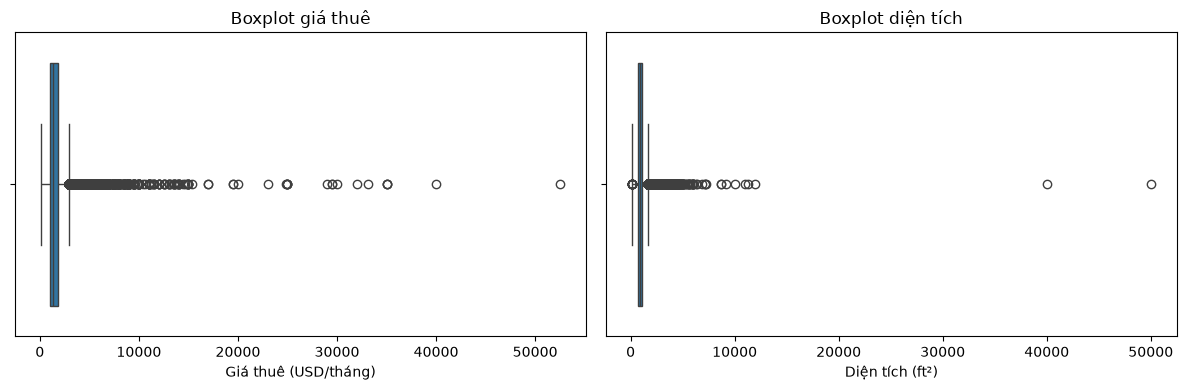

In [70]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    x=df_apartment["price"],
    ax=axes[0]
)
axes[0].set_title("Boxplot giá thuê")
axes[0].set_xlabel("Giá thuê (USD/tháng)")

sns.boxplot(
    x=df_apartment["square_feet"],
    ax=axes[1]
)
axes[1].set_title("Boxplot diện tích")
axes[1].set_xlabel("Diện tích (ft²)")

plt.tight_layout()
plt.show()


**Nhận xét:**
1. Không phát hiện giá thuê, diện tích, bedroom và bathroom có giá trị bất thường
2. Với IQR, price có 4.695 giá trị ngoại lại nằm ngoài -160 đến 2968 USD. square_feet cso 2840 giá trị ngoài lai, khoảng 150 đến 1694 ft^2
3. Hai biểu đồ boxplot cho thấy phần lớn giá thuê và diện tích tập trung trong một khoảng tương đối hẹp, trong khi nhiều điểm ngoại lai nằm xa về phía giá trị lớn. Một số tin có giá lên tận 50000 USD và diên tích khoảng 50000 ft^2
- Nhìn chung dữ liệu có nhiều gia trị ngoại lai ở thuộc tính giá thuê và diện tích.

### 3.6. Xử lý dữ liệu và kiểm tra kết quả
Dựa trên các kết quả kiểm tra ở các mục trước, thực hiện loại bỏ những bản ghi trùng lặp, giới hạn dữ liệu trong phạm vi căn hộ cho thuê theo tháng và xử lý giá trị thiếu ở thuộc tính giá thuê.

Các thuộc tính thiếu thông tin và giá trị ngoại lai khác được giữ lại để tránh làm mất dữ liệu vì một số chiếm phần lớn.

#### Loại bỏ các bản ghi trùng hoàn toàn

In [71]:
df_clean = df.copy()

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

print("Số bản ghi ban đầu:", rows_before)
print("Số bản ghi trùng đã loại bỏ:",
      rows_before - len(df_clean))
print("Số bản ghi còn lại:", len(df_clean))

Số bản ghi ban đầu: 99492
Số bản ghi trùng đã loại bỏ: 84
Số bản ghi còn lại: 99408


#### Lọc dữ liệu theo phạm vi và xử lý giá thuê thiếu
Vì bài được em xác định tập trung vào căn hộ cho thuê và giá theo tháng nên giới hạn dữ liệu theo điều kiện

In [72]:
rows_before = len(df_clean)

df_clean = df_clean.loc[
    (df_clean["category"] == "housing/rent/apartment") &
    (df_clean["price_type"] == "Monthly")
].copy()

print("Số bản ghi ngoài phạm vi đã loại bỏ:",
      rows_before - len(df_clean))

rows_before = len(df_clean)

df_clean = df_clean.dropna(subset=["price"]).copy()

print("Số bản ghi thiếu giá thuê đã loại bỏ:",
      rows_before - len(df_clean))

df_clean = df_clean.reset_index(drop=True)

print("Số bản ghi sau xử lý:", len(df_clean))

Số bản ghi ngoài phạm vi đã loại bỏ: 65
Số bản ghi thiếu giá thuê đã loại bỏ: 1
Số bản ghi sau xử lý: 99342


#### Kiểm tra kết quả sau khi làm sạch

In [73]:
print("Dữ liệu gốc:", df.shape)
print("Dữ liệu sau làm sạch:", df_clean.shape)

print("Bản ghi trùng hoàn toàn:",
      df_clean.duplicated().sum())

print("ID trùng:",
      df_clean["id"].duplicated().sum())

print("Giá thuê bị thiếu:",
      df_clean["price"].isnull().sum())

print("Tin đăng không thuộc loại căn hộ:",
      (df_clean["category"] != "housing/rent/apartment").sum())

print("Kỳ thanh toán không phải Monthly:",
      (df_clean["price_type"] != "Monthly").sum())

print("Số thuộc tính còn giá trị thiếu:",
      (df_clean.isnull().sum() > 0).sum())


Dữ liệu gốc: (99492, 22)
Dữ liệu sau làm sạch: (99342, 22)
Bản ghi trùng hoàn toàn: 0
ID trùng: 0
Giá thuê bị thiếu: 0
Tin đăng không thuộc loại căn hộ: 0
Kỳ thanh toán không phải Monthly: 0
Số thuộc tính còn giá trị thiếu: 9


**Nhận xét:**
1. Đã loại bỏ 84 dòng trùng hoàn toàn, số dòng giảm từ 99492 xuống còn 99408
2. Tiếp tục loại bỏ 65 bản ghi không thuộc phạm vi căn hộ cho thuê theo tháng và 1 bản ghi thieus giá thêu. Dữ liệu còn 99342 bản ghi
3. Kết quả kiểm tra cho thấy không còn bản ghi trùng hoàn toàn, id trùng lặp, giá thiếu hoặc tin không thuộc phạm vi cho thuê. Số thuộc tính vẫn là 22
- Dữ liệu vẫn còn 9 thuộc tính có giá trị thiếu. Các giá trị này được giữ lại vì em tránh làm mất thông tin khi một số có số lượng quá lớn.

## 4. Thống kê mô tả và trực quan hóa dữ liệu
### 4.1. Các đại lượng đo xu hướng trung tâm
Sử dụng các đại lượng mean (TB), median (TV), mode (YV) để tìm các giá trị trung của các thuộc tính price, square_feet, bedrooms, bathrooms

#### Tính mean, median và mode

In [74]:
columns = ["price", "square_feet", "bedrooms", "bathrooms"]

df_central = pd.DataFrame({
    "Trung bình (Mean)": df_clean[columns].mean(),
    "Trung vị (Median)": df_clean[columns].median(),
    "Yếu vị (Mode)": df_clean[columns].mode().iloc[0]
})

display(df_central.round(2))


,Trung bình (Mean),Trung vị (Median),Yếu vị (Mode)
price,1526.92,1350.0,1350.0
square_feet,956.36,900.0,1000.0
bedrooms,1.73,2.0,2.0
bathrooms,1.45,1.0,1.0


**Nhận xét:**
- Price có giá trị trung bình khoảng 1526,26 USD trên tháng, trung vị và yêu vị là 1350 USD. Giá trị trung bình cao hơn trung vị, có thể bị ảnh hưởng do một số tin có giá cao
- square_feet có diện tích trung bình khoảng 956.36 ft^2, trung vị 900 ft^2 và xuất hiện nhiều nhất là 1000 ft^
- bedrooms có trung bình khoảng 1,73 phòng , trung vị và yếu vị đều là 2 cho thấy căn hộ có 2 phòng ngủ xuất hiện nhiều nhất
- bathrooms có trung bình khoảng 1,45 phòng, trung vị và yêu vị đều là 1 cho thấy 1 phòng tắm xuất hiện nhiều nhất
- Nhìn chung các đại lương đo xu hướng trung giúp xác định những giá trị thường gặp của giá, diện tích, số phòng ngủ và vệ sinh trong bộ dữ liệu. Sự chênh lệch giữa trung bình và trung vị có thể bắt nguồn từ một số bản tin có giá trị cao đột biến

### 4.2. Các đại lượng đo độ phân tán
Sử dụng các đại lượng min, max, range, tứ phân vị, iqr, phương sai và độ lệch chuẩn để tìm hiểu mức độ phân tán cả giá, diện tích, số phòng ngủ, phòng vệ sinh trong bộ dữ liệu sau khi làm sạch

#### Tính max, min, range và tứ phân vị

In [75]:
stats_cols = ["price", "square_feet", "bedrooms", "bathrooms"]

df_quartiles = pd.DataFrame({
    "Min": df_clean[stats_cols].min(),
    "Max": df_clean[stats_cols].max(),
    "Range": df_clean[stats_cols].max() - df_clean[stats_cols].min(),
    "Q1 (25%)": df_clean[stats_cols].quantile(0.25),
    "Q2 (50%)": df_clean[stats_cols].median(),
    "Q3 (75%)": df_clean[stats_cols].quantile(0.75),
    "IQR": df_clean[stats_cols].quantile(0.75) - df_clean[stats_cols].quantile(0.25)
})

display(df_quartiles.round(2))

,Min,Max,Range,Q1 (25%),Q2 (50%),Q3 (75%),IQR
price,100.0,52500.0,52400.0,1013.00,1350.0,1795.0,782.00
square_feet,101.0,50000.0,49899.0,728.25,900.0,1115.0,386.75
bedrooms,0.0,9.0,9.0,1.00,2.0,2.0,1.00
bathrooms,1.0,9.0,8.0,1.00,1.0,2.0,1.00


#### Tính phương sai và độ lệch chuẩn


In [76]:
df_variation = pd.DataFrame({
    "Phương sai (Variance)": df_clean[stats_cols].var(),
    "Độ lệch chuẩn (Std)": df_clean[stats_cols].std()
})

display(df_variation.round(2))

,Phương sai (Variance),Độ lệch chuẩn (Std)
price,817707.89,904.27
square_feet,174369.96,417.58
bedrooms,0.56,0.75
bathrooms,0.30,0.55


**Nhận xét:**
- price có khoảng biến thiên lớn, từ 100 đến 52500 USD một tháng, với IQR là 782 đô, phương sai đạt 817707,89 và độ lệch chuẩn khoảng 904,27 USD cho thấy giá thuê có sự phân tán đáng kể
- square_feet dao động từ 101 đến 50000 ft^2, IQR là 386.75, có độ lệch chuẩn khoảng 417,58. Khoảng biên thiên lớn cho thấy có sự chênh lệch đáng kể về diện tích giữa các tin.
- bedrooms có giá trị từ 0-9, IQR bằng 1 và độ lệch chuẩn khoảng 0,75 cho thấy số phòng ngủ trong một khoảng khá hẹp
- bathrooms dao đôg từ 1 đén 9, IQR cũng bằng 1, độ lệch chuẩn khoảng 0,55 cho thấy mức độ phân tán tương đối thấp
- Nhìn chung giá thuê và diện tích có khoảng biến thiên lớn. Trong khi số phòng ngủ và phòng tắm tập trung trong phạm vi hẹp hơn

### 4.3. Độ lệch và độ nhọn của phân phối
Sử dụng skewness và kurtosis để xem xét hình dạng phân phối của các thuộc tính price, square_feet, bedrooms và bathrooms trong bộ dữ liệu sau khi làm sạch

#### Tính skewness và kurtosis

In [77]:
df_distribution = pd.DataFrame({
    "Skewness": df_clean[stats_cols].skew(),
    "Excess Kurtosis": df_clean[stats_cols].kurt()
})

display(df_distribution.round(2))

,Skewness,Excess Kurtosis
price,9.97,307.25
square_feet,27.16,2713.79
bedrooms,0.88,1.60
bathrooms,0.99,2.31


**Nhận xét:** 
- price: skewness = 9,97 cho thấy độ phân phối lệch phải rất mạnh, kurtosis = 307.25 cho thấy phân phosois có đuôi rất nặng với sự xuất hiện của các giá trị cực lớn
square_feet có skewness = 27,16 và kurtosis 2713,79 cho thấy phân phổi lệch phải rất mạnh và có độ nhọn rất caom phản ảnh sự xuất hiện của giá trị diện tích cực lớn so với phân còn lại của dữ liệu
- bedrooms: skewness là 0,88 cho thấy phân phối lệch phải, kurtosis là 1,6 cho thấy đuối phân phối nặng hơn phân phối chuẩn
- bathrooms có skewness là 0,99 cho thấy phân phối lệch phải, kurtosis là 2,31 cho thấy đuối phân phối năng hơn phân phối chuẩn
- Nhìn chung cả 4 thuộc tính đều có phân phối lệch phải, trong đó price và square_feet có mức độ lệch và độ nhọn lớn nhất

### 4.4. Các biểu đồ thống kê dữ liệu
Sử dụng các loại biểu đồ thống kê để trực quan hóa sự phân bố và đặc điểm của bộ dữ liệu. Các biểu đồ tập trung vào giá, diện tích, số phòng ngủ và một số thuộc tính của tin.

#### Biểu đồ Histogram phân phối giá thuê
Quan sát các khoảng giá thuê có nhiều tin đăng, đồng thời tìm hiểu hình dạng phân phối

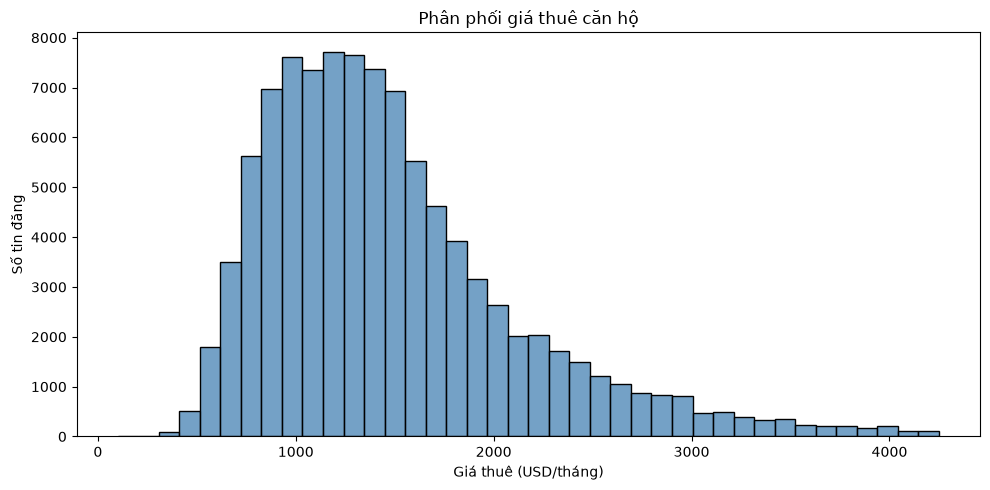

In [78]:
price_p99 = df_clean["price"].quantile(0.99)
df_price_plot = df_clean[df_clean["price"] <= price_p99]

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_price_plot,
    x="price",
    bins=40,
    color="steelblue"
)

plt.title("Phân phối giá thuê căn hộ")
plt.xlabel("Giá thuê (USD/tháng)")
plt.ylabel("Số tin đăng")

plt.tight_layout()
plt.show()

**Nhận xét**
- Biểu đồ Histogram cho thấy giá thuê tập trung nhiều ở khoảng 800–2000 USD, trong đó các khoảng giá gần 1000–1500 USD có số lượng tin đăng cao nhất
- Khi giá thuê tăng lên trên 2000 USD, số lượng tin đăng có xu hướng giảm dần. Các mức giá từ 3000 USD trở lên xuất hiện ít hơn
- Phân phối có xu hướng lệch phải, khi phần lớn dữ liệu tập trung ở mức giá thấp và trung bình, còn phần đuôi kéo dài về phía giá trị lớn. Điều này phù hợp với kết quả Skewness = 9,97
- Giá thuê trung bình là 1526,92 USD và trung vị là 1350 USD cũng cho thấy giá trị trung bình cao hơn trung vị

#### Biểu đồ countplot số phòng ngủ
So sánh số lượng tin theo số phòng ngủ

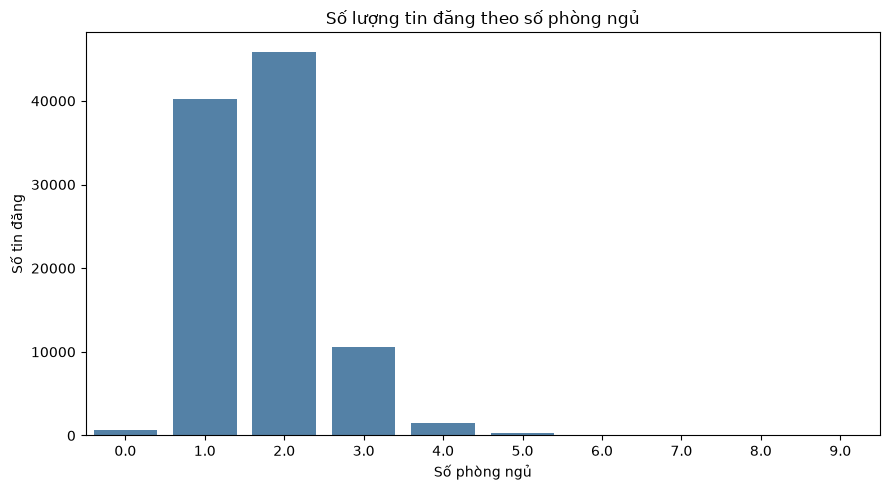

In [79]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="bedrooms",
    order=sorted(df_clean["bedrooms"].dropna().unique()),
    color="steelblue"
)

plt.title("Số lượng tin đăng theo số phòng ngủ")
plt.xlabel("Số phòng ngủ")
plt.ylabel("Số tin đăng")

plt.tight_layout()
plt.show()


**Nhận xét**
- Biểu đồ cho thấy nhóm căn hộ có 2 phòng ngủ chiếm số lượng nhiều nhất, khoảng 46000 tin đăng, tiếp theo là nhóm 1 phòng ngủ với khoảng 40000 tin đăng
- Nhóm 3 phòng ngủ có số lượng thấp hơn khá nhiều, khoảng 10000–11000 tin đăng. Các nhóm từ 4 phòng ngủ trở lên có số lượng giảm mạnh
- Các tin đăng có từ 5 đến 9 phòng ngủ xuất hiện rất ít so với nhóm 1 và 2 phòng ngủ. Ngoài ra, dữ liệu cũng có một số tin đăng ghi nhận 0 phòng ngủ



#### Biểu đồ bar giá thuê trung vị theo số phòng ngủ
So sánh giá thuê trung vị giữa các nhóm căn hộ có số phòng ngủ khác nhau

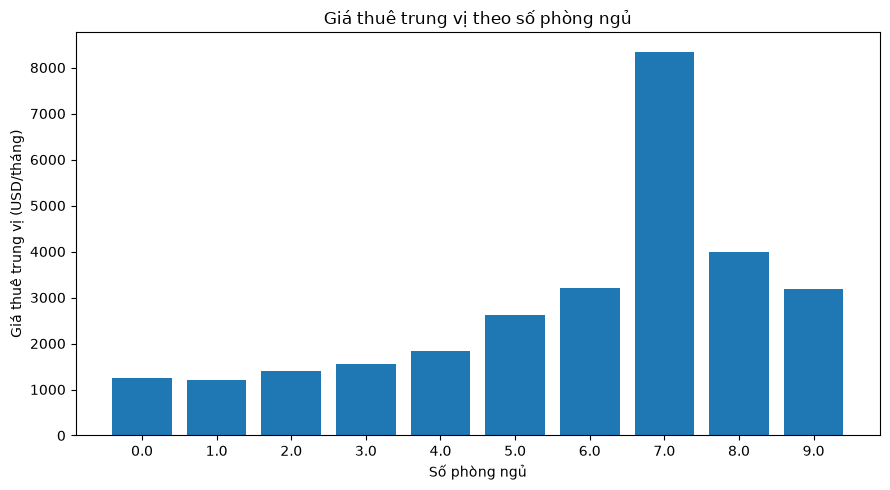

In [80]:

median_price = df_clean.groupby("bedrooms")["price"].median()

plt.figure(figsize=(9, 5))

plt.bar(
    median_price.index.astype(str),
    median_price.values
)

plt.title("Giá thuê trung vị theo số phòng ngủ")
plt.xlabel("Số phòng ngủ")
plt.ylabel("Giá thuê trung vị (USD/tháng)")

plt.tight_layout()
plt.show()


**Nhận xét**
- Biểu đồ cho thấy giá thuê trung vị nhìn chung có xu hướng tăng khi số phòng ngủ tăng, đặc biệt từ nhóm 1 đến 7 phòng ngủ
- Nhóm căn hộ 1 phòng ngủ có giá thuê trung vị khoảng 1200 USD/tháng, nhóm 2 phòng ngủ khoảng 1400 USD, còn nhóm 3 phòng ngủ khoảng 1550 USD
- Với các nhóm từ 4 đến 6 phòng ngủ, giá thuê trung vị tiếp tục tăng, đạt khoảng 3200 USD ở nhóm 6 phòng ngủ
- Nhóm 7 phòng ngủ có giá thuê trung vị cao nhất, khoảng 8300 USD. Tuy nhiên, nhóm 8 và 9 phòng ngủ lại có giá thuê trung vị thấp hơn, lần lượt khoảng 4000 và 3200 USD

#### Biểu đồ scatterplot diện tích và giá thuê
Quan sát xem diện tích và giá thuê có xu hướng biến động cùng nhau hay không

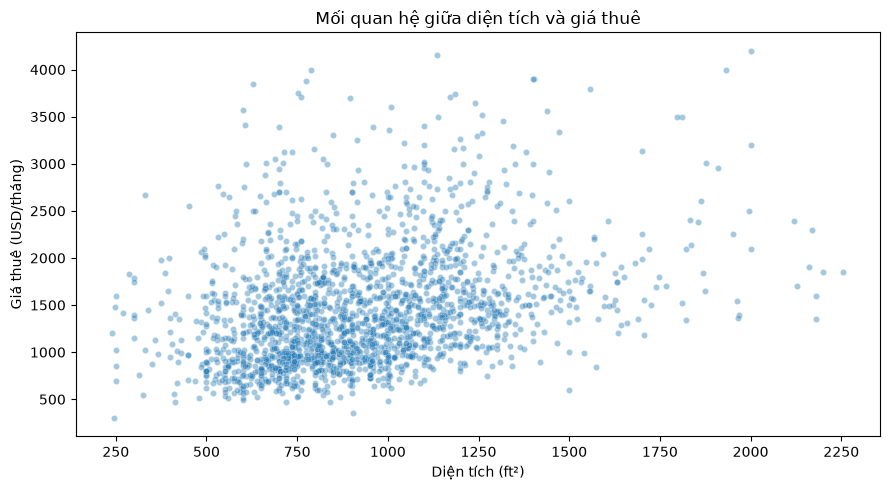

In [81]:

df_scatter = df_clean[
    (df_clean["price"] <= df_clean["price"].quantile(0.99)) &
    (df_clean["square_feet"] <= df_clean["square_feet"].quantile(0.99))
]

df_scatter = df_scatter.sample(n=2000, random_state=42)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_scatter,
    x="square_feet",
    y="price",
    alpha=0.4,
    s=20
)

plt.title("Mối quan hệ giữa diện tích và giá thuê")
plt.xlabel("Diện tích (ft²)")
plt.ylabel("Giá thuê (USD/tháng)")

plt.tight_layout()
plt.show()


**Nhận xét**
- Biểu đồ Scatterplot cho thấy các điểm dữ liệu có xu hướng đi lên từ trái sang phải, thể hiện mối liên hệ thuận giữa diện tích và giá thuê. Những căn hộ có diện tích lớn hơn thường có xu hướng được đăng với giá cao hơn.
- Phần lớn các điểm tập trung ở khoảng diện tích 500–1300 ft^2, với giá thuê chủ yếu từ khoảng 600–2000 USD
- Tuy nhiên, các điểm phân bố khá rộng. Ở cùng một mức diện tích, giá thuê vẫn có thể chênh lệch đáng kể giữa các tin đăng
- Biểu đồ cũng xuất hiện một số căn hộ có diện tích không quá lớn nhưng giá thuê cao, trong khi một số căn hộ có diện tích lớn hơn lại có mức giá thấp hơn

#### Biểu đồ pie trạng thái hình ảnh
Quan sát tỷ trọng các trạng thái Yes, Thumbnail và No trong bộ dữ liệu

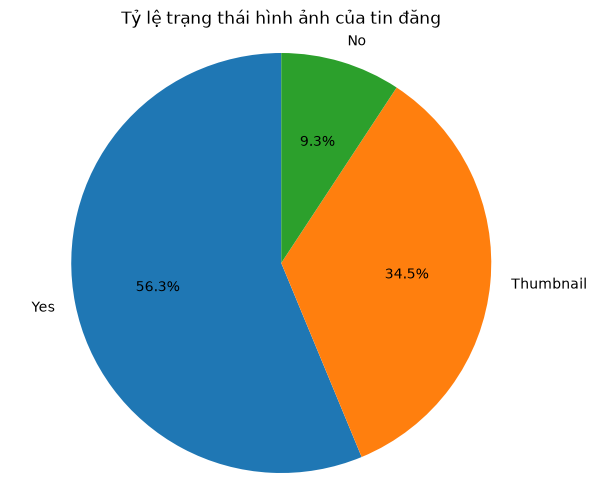

In [82]:

photo_counts = df_clean["has_photo"].value_counts()

plt.figure(figsize=(7, 6))

plt.pie(
    photo_counts.values,
    labels=photo_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Tỷ lệ trạng thái hình ảnh của tin đăng")
plt.axis("equal")
plt.show()


**Nhận xét**
- Biểu đồ Pie chart cho thấy trạng thái Yes chiếm tỷ lệ cao nhất với 56,3%, tương ứng hơn một nửa số tin đăng trong bộ dữ liệu
- Trạng thái Thumbnail chiếm 34,5%, đứng thứ hai trong ba nhóm.
- Trạng thái No có tỷ lệ thấp nhất, chỉ 9,3%
- Tổng tỷ lệ của hai trạng thái Yes và Thumbnail khoảng 90,8%, cho thấy phần lớn tin đăng có trạng thái hình ảnh được ghi nhận khác No.

**Nhận Xét**
1. Giá thuê tập trung nhiều trong khoảng 1000–2000 USD, với phân phối lệch phải và số lượng tin đăng giảm dần ở những mức giá cao
2. Các căn hộ có 1–2 phòng ngủ xuất hiện nhiều nhất trong dữ liệu. Giá thuê trung vị nhìn chung tăng theo số phòng ngủ, nhưng có sự chênh lệch ở các nhóm có ít tin đăng
3. Diện tích và giá thuê có dấu hiệu liên hệ thuận, tuy nhiên các điểm dữ liệu phân tán khá rộng, cho thấy diện tích không phải yếu tố duy nhất liên quan đến giá thuê
4. Về trạng thái hình ảnh, phần lớn tin đăng thuộc nhóm Yes hoặc Thumbnail, chiếm khoảng 90,8%

## 5. Phân phối xác suất
### 5.1. Phân phối nhị thức (Binomial)
Sử dụng phân phối nhị thức để tính xác suất chọn được các tin ddawdng có 2 phòng ngủ trong bộ dữ liệu

Giả sử thực hiện 10 lượt chọn ngẫu nhiên độc lập, từ những tin đăng có thông tin số phòng ngủ. Mỗi lượt chọn có 2 kết quả: tin đăng có đúng 2 phòng ngủ hoặc không

Xác suất thành công p được ước lượng từ tỷ lệ tin đăng có 2 phòng ngủ trong df_clean

#### Xác định tham số và tính xác suất

In [83]:
from scipy.stats import binom

bedrooms_valid = df_clean["bedrooms"].dropna()

p = (bedrooms_valid == 2).mean()

n = 10
k = 5

prob_exact = binom.pmf(k, n, p)

prob_at_least = 1 - binom.cdf(k - 1, n, p)

print("Số tin đăng hợp lệ:", len(bedrooms_valid))
print("Số tin đăng có 2 phòng ngủ:",
      (bedrooms_valid == 2).sum())
print(f"Xác suất thành công p: {p:.4f}")

print(f"P(X = 5): {prob_exact:.4f}")
print(f"P(X >= 5): {prob_at_least:.4f}")

print("Kỳ vọng:", round(n * p, 2))
print("Phương sai:", round(n * p * (1 - p), 2))

Số tin đăng hợp lệ: 99219
Số tin đăng có 2 phòng ngủ: 45900
Xác suất thành công p: 0.4626
P(X = 5): 0.2393
P(X >= 5): 0.5283
Kỳ vọng: 4.63
Phương sai: 2.49


**Nhận xét**
- Trong 99.219 tin hợp lệ về số phòng ngủ, có khoảng 45900 tin có đúng 2 phòng ngủm tương ứng tỉ lệ 46,26%. Tỷ lệ này được dùng làm xác suất thành công p = 0,4626 trong mô hình nhị thức
- Với 10 lượt chọn ngẫu nhiên độc lập, có hoàn lại, xác suất chọn được đúng 5 tin đăng có 2 phòng ngủ 23,93%
- Xác suất chọn được ít nhất 5 tin đăng có 2 phòng ngủ là 52,83%, tức xác suất 5-10 lần thành công
- Kỳ vọng bàng 4,63 cho thấy số lần thành công trung bình theo mô hình trong 10 lượt chọn khoảng 4-5 lần. Phương sai bằng 2,49 thể hiện mức độ biến động của số lần thành công quanh kỳ vọng

=> Có thể sử dụng tỉ lệ tin đăng có 2 phòng ngủ trong dataset để xây dựng mô hình nhị thức và tính xác suất cho những trường hợp lựa chọn khác nhau 

#### Bảng phân phối xác suất và biểu đồ
Biểu đồ thể hiện xác suất xảy ra của từng số lần thành công khi thực hiện 10 lượt chọn.

Đây là biểu đồ phân phối xác suất lý thuyết dựa trên tham số p ước lượng



,Số lần thành công (k),P(X = k)
0,0,0.0020
1,1,0.0173
2,2,0.0670
3,3,0.1538
4,4,0.2316
5,5,0.2393
6,6,0.1717
7,7,0.0844
8,8,0.0273
9,9,0.0052


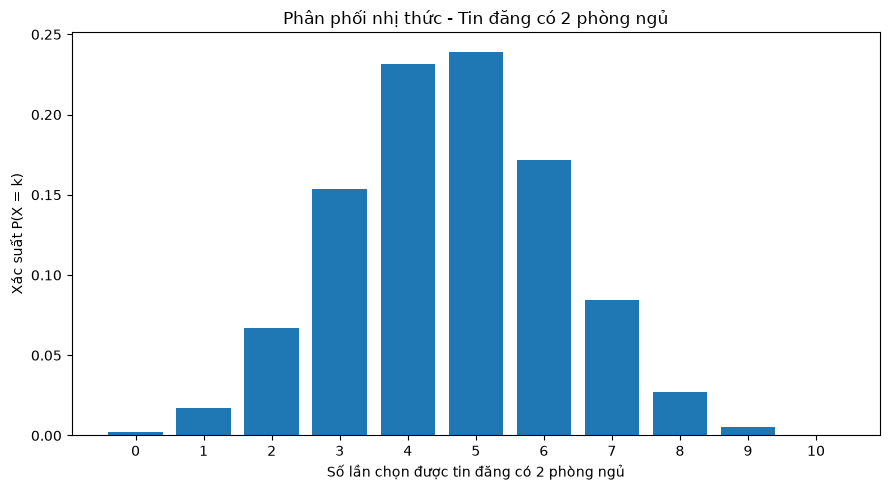

In [84]:

import matplotlib.pyplot as plt

k_values = list(range(n + 1))

probabilities = binom.pmf(k_values, n, p)

df_binomial = pd.DataFrame({
    "Số lần thành công (k)": k_values,
    "P(X = k)": probabilities
})

display(df_binomial.round(4))

plt.figure(figsize=(9, 5))

plt.bar(k_values, probabilities)

plt.title("Phân phối nhị thức - Tin đăng có 2 phòng ngủ")
plt.xlabel("Số lần chọn được tin đăng có 2 phòng ngủ")
plt.ylabel("Xác suất P(X = k)")
plt.xticks(k_values)

plt.tight_layout()
plt.show()


**Nhận xét**
- Bảng phân phối và biểu đồ cho thấy xác suất tăng dần từ k=0 đén k=5, sau đó giảm dần khi số lần thành công tiếp tục tăng
- Xác suất cao nhất tại k = 5 khi đặt 23,93%, tiếp thoe là k=4 với 23,16% và k=6 với 17,17%. Điều này cho thấy số lần thành công có khả năng xảy ra cao thường tập trung quanh 4-6 lần trong 10 lần chọn
- Các trường hợp có số lần thành công quá thấp hoặc quá cao có xác suất nhỏ. Ví dụ xác suất không chọn được tin nào có 2 phòng ngủ là 0,20% trong khi chọn được cả 10 lượt là 0,04%
- Biểu đồ có dạng một đỉnh tập trung quanh kỳ vọng 4,63 và có độ lệch nhệ về phía các giá trị thấp do p=0,4626 nhỏ hơn 0,5

=> Phân phối nhị thức cho thấy số lần chọn được tin đăng có 2 phòng ngủ thường tập trung ở vùng giữa, còn các trường hợp quá ít hoặc quá nhiều thành công có xác suất thấp hơn

**Kết luận chung**
Kết quả cho thấy xác suất thành công trong mỗi lượt chọn khoảng 46,26%, với số lần thành công kỳ vọng là 4,63 lần. Trường hợp có đúng 5 lần thành công có xác suất cao nhất (23,93%), còn xác suất có ít nhất 5 lần thành công đạt 52,83%.

### 5.2. Phân phối Poisson
Sử dụng phân phối poisson để xấp xỉ xác suất xuất hiện các tin đăng có từ 4 phòng ngủ trở lên trong data set

Giả sử thực hiện 100 lượt chọn ngẫu nhiên độc lập có hoàn lại, từ những tin đã có thông tin số phòng ngủ. Tỷ lệ tin đăng có từ 4 phòng ngủ trở lên được sử dụng để ước lượng số sự kiện trung bình lamda trong 100 lượt chọn 

#### Xác định tham số lamda và tính xác suất

In [85]:

from scipy.stats import poisson

bedrooms_valid_poisson = df_clean["bedrooms"].dropna()

p_rare = (bedrooms_valid_poisson >= 4).mean()

n_group = 100

lambda_poisson = n_group * p_rare

prob_2 = poisson.pmf(2, lambda_poisson)

prob_at_least_3 = 1 - poisson.cdf(2, lambda_poisson)

print("Số tin đăng hợp lệ:", len(bedrooms_valid_poisson))
print("Số tin đăng có từ 4 phòng ngủ:",
      (bedrooms_valid_poisson >= 4).sum())

print(f"Tỷ lệ sự kiện p: {p_rare:.4f}")
print(f"Lambda: {lambda_poisson:.4f}")

print(f"P(X = 2): {prob_2:.4f}")
print(f"P(X >= 3): {prob_at_least_3:.4f}")

print(f"Kỳ vọng: {lambda_poisson:.4f}")
print(f"Phương sai: {lambda_poisson:.4f}")


Số tin đăng hợp lệ: 99219
Số tin đăng có từ 4 phòng ngủ: 1837
Tỷ lệ sự kiện p: 0.0185
Lambda: 1.8515
P(X = 2): 0.2691
P(X >= 3): 0.2832
Kỳ vọng: 1.8515
Phương sai: 1.8515


**Nhận xét**
- Có 99219 tin hợp lệ, có 1837 tin có từ 4 phòng ngủ trở lên, chiểm 1,85%. Tỷ lệ này tương đối nhỏ nên cotheer sử dụng phân phối Poisson để xấp xỉ số lần xuất hiện của nhóm tin này trong 100 lượt chọn.
- Tham số lamda = 1,8515 cho biết trong 100 lượt chọn ngẫy nhiên độc lập, số tin có từ 4 phòng ngủ trở lên kỳ vọng khoảng 1,85 lần
- Xác suất xuất hiện đúng 2 tin đăng có từ 4 phòng ngủ trở lên là 26,91% trong khi xác suất xuất hiện ít nhất là 3 tin đăng là 28,32%
- Kỳ vọng và phương sai đều bằng 1,8515 phù hợp với đặc điểm của phần phối Poisson

=> Kêt quả cho tháy nhóm tin có từ 4 phòng ngủ trở lên chiếm tỷ lệ thấp trong tập dữ liệu, và mô hình Poisson giúp ước lượng xác suất xuất hiện nhóm này trong một số lượt chọn nhất định

#### Bảng phân phối xác suất và biểu đồ Poisson
Phân phối poisson có thể nhận mọi giá trị nguyên không âm

Chỉ hiển thị 0-10 để biểu đồ gọn, không phải giới hạn toàn bộ phân phối



,Số sự kiện (k),P(X = k)
0,0,0.1570
1,1,0.2907
2,2,0.2691
3,3,0.1661
4,4,0.0769
5,5,0.0285
6,6,0.0088
7,7,0.0023
8,8,0.0005
9,9,0.0001


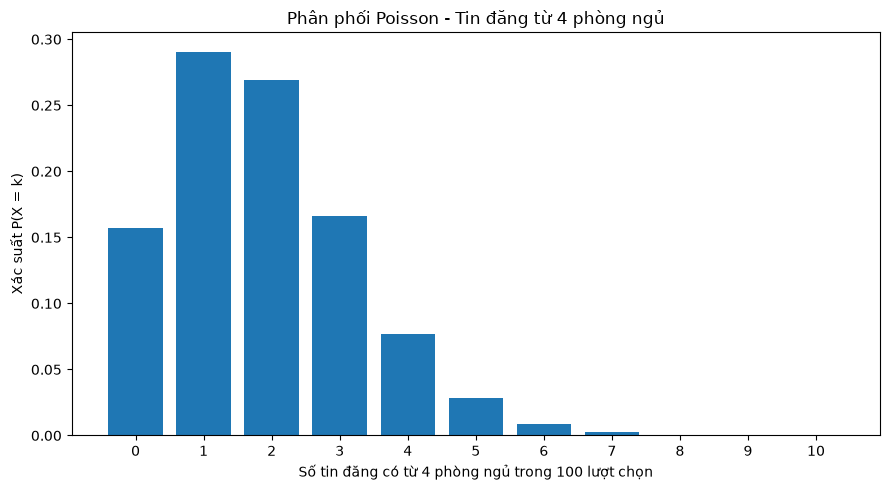

In [86]:

import matplotlib.pyplot as plt

k_values = list(range(11))

probabilities = poisson.pmf(k_values, lambda_poisson)

df_poisson = pd.DataFrame({
    "Số sự kiện (k)": k_values,
    "P(X = k)": probabilities
})

display(df_poisson.round(4))

plt.figure(figsize=(9, 5))

plt.bar(k_values, probabilities)

plt.title("Phân phối Poisson - Tin đăng từ 4 phòng ngủ")
plt.xlabel("Số tin đăng có từ 4 phòng ngủ trong 100 lượt chọn")
plt.ylabel("Xác suất P(X = k)")
plt.xticks(k_values)

plt.tight_layout()
plt.show()


**Nhận xét**
- Bảng phân phối và biểu đồ cho thấy xác suất cao nhất tại k=1 khi đạt 29,07%, sau là k=2 với 26,91% và k3 với 16,61%
- Xác suất không chọn được tin đăng nào có từ 4 phòng ngủ trở lên là 15,70%, cho thấy trường hợp không có lần thành công nào vẫn có khả năng xảy ra cao
- Khi số sự kiện tăng từ 3 lần trở lên lên, xác suất cso xu hướng giảm dần, ví dụ xác suất xuất hiện đúng 5 sự kiện chỉ còn 2,85%, 7 sự kiện chỉ khoảng 0,23%
- Biểu đồ có dạng lệch phải, tập trung nhiều ở các giá trị k từ 0 đến 3. Các trường hợp có só sự kiện lớn hơn xuất hiện với xác suất rất thấp.

=> Nhìn chung, số lần xuất hiện của tin có từ 4 phòng ngủ trở lên theo mô hình Poisson thường tập trung quanh 1-2 lần trong 100 lượt chọn.

**Kết luận chung**
Kết quả cho thấy tỷ lệ sự kiện khoảng 1,85%, với tham số λ = 1,8515. Xác suất xuất hiện đúng 1 sự kiện là cao nhất (29,07%), tiếp theo là 2 sự kiện (26,91%). Những trường hợp xuất hiện nhiều sự kiện có xác suất thấp hơn.

## 6. Kiểm định giả thuyết thống kê
### 6.1. Kiểm định T-Test
Sử dụng kiểm định T-test hai mẫu độc lập để keierm tra sự khác biệt về giá thuê trung bình giữa các căn hộ có 1 phòng ngủ và 2 phòng ngủ trong bộ dữ liệu

Giả thuyết kiểm định:
- H0: Giá thuê trung bình của hai nhóm căn hộ bằng nhau
- H1: Giá thuê trung bình của hai nhóm căn hộ khác nhau

Chọn mức ý nghĩa alpha = 0,05 (0,5%)

#### Chuẩn bị và kiểm tra hai nhóm dữ liệu
Xem số lượng bản ghi, giá trung bình, độ lệch chuẩn của từng nhóm. Các chỉ số giúp chuẩn bị và giải thích trực tiếp kết quả của T-test

In [87]:
price_1bed = df_clean.loc[
    df_clean["bedrooms"] == 1, "price"
].dropna()

price_2bed = df_clean.loc[
    df_clean["bedrooms"] == 2, "price"
].dropna()

df_ttest_groups = pd.DataFrame({
    "Số bản ghi": [len(price_1bed), len(price_2bed)],
    "Giá trung bình": [price_1bed.mean(), price_2bed.mean()],
    "Độ lệch chuẩn": [price_1bed.std(), price_2bed.std()]
}, index=["1 phòng ngủ", "2 phòng ngủ"])

display(df_ttest_groups.round(2))


,Số bản ghi,Giá trung bình,Độ lệch chuẩn
1 phòng ngủ,40278,1346.79,595.44
2 phòng ngủ,45900,1579.36,800.30


**Nhận xét**
- Nhóm căn hộ 1 phòng ngủ: Có 40278 dòng, giá trung bình khoảng 1346,79 USD, và độ lệch chuẩn là 595,44 USD
- Nhóm căn hộ 2 phòng ngủ: Có 45900 dòng, giá trung bình khoảng 1579,36 USD, và độ lệch chuẩn là 800,30 USD
- Giá thuê trung bình của nhóm 2 phòng cao hơn nhóm 1 phòng, khoảng 232,57 USD
- Độ lệch chuẩn của nhóm 2 phòng cũng lớn hơn, cho thấy giá thuê của nhóm này có mức độ phân tán cao hơn

=> Kết quả thống kê ban đầu cho thấy có sự chênh lệch về giá trung bình giữa 2 nhóm căn hộ

#### Thực tế kiểm định T-test
Quy tắc kết luận:
- p-value < 0,05: Bác bỏ H0, có bằng chứng về sự khác biệt trung bình
- p_value >= 0,05: Không đủ cơ sở bác bỏ H0

In [88]:

from scipy import stats

alpha = 0.05

t_stat, p_value = stats.ttest_ind(
    price_1bed,
    price_2bed,
    equal_var=False
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Mức ý nghĩa alpha: {alpha}")

if p_value < alpha:
    print("Bác bỏ H0.")
    print("Giá thuê trung bình của hai nhóm khác nhau")
    print("có ý nghĩa thống kê.")
else:
    print("Không đủ cơ sở bác bỏ H0.")
    print("Chưa có đủ bằng chứng về sự khác biệt")
    print("giá thuê trung bình giữa hai nhóm.")


T-statistic: -48.7526
P-value: 0
Mức ý nghĩa alpha: 0.05
Bác bỏ H0.
Giá thuê trung bình của hai nhóm khác nhau
có ý nghĩa thống kê.


**Nhận xét**
- Kết quả kiểm định T-Test cho thấy T-statistic = -48,7526 và p-value bằng 0 do giá trị thực tế cực nhỏ
- Mức ý nghĩa alpha = 0,05, có p-value nhỏ hơn α nên bác bỏ giả thuyết H0
- Kết quả cho thấy có sự khác biệt có ý nghĩa thống kê về giá thuê trung bình giữa nhóm căn hộ 1 phòng ngủ và 2 phòng ngủ
- Giá trị T-statistic âm phù hợp với việc giá thuê trung bình của nhóm 1 phòng ngủ thấp hơn nhóm 2 phòng ngủ theo thứ tự đưa vào kiểm định

=> Vậy, ở mức ý nghĩa 5%, có đủ bằng chứng thống kê để kết luận rằng giá thuê trung bình của hai nhóm căn hộ khác nhau.

**Kết luận chung**
Kết quả cho thấy nhóm căn hộ 2 phòng ngủ có giá thuê trung bình cao hơn khoảng 232,57 USD/tháng. Với T-statistic = -48,7526 và p-value rất nhỏ so với mức ý nghĩa 0,05, giả thuyết H0 bị bác bỏ.

Nhìn chung, kết quả kiểm định cho thấy sự khác biệt về giá thuê trung bình giữa hai nhóm có ý nghĩa thống kê.

### 6.2 Kiểm định Z-Test
Sử dụng kiểm định Z-test một mẫu để kiểm tra xem diện tích trung bình của các căn hộ trong bộ dữ liệu có khác mức tham chiếu giả định 1000 ft^2 không

Giả thuyết kiểm định:
- H0: diện tích trung bình của căn hộ bằng 1000 ft^2
- H1: diện tích trung bình của căn hộ khác 1000 ft^2

Chọn mức ý nghĩa alpha = 0,05 (0,5%)

#### Chuẩn bị và thống kê dữ liệu
Kiểm tra số lượng quan sát, diện tích trung bình và độ lệch chuẩn trước khi kiểm định

In [89]:

area_valid = df_clean["square_feet"].dropna()

mu0 = 1000

print("Số bản ghi hợp lệ:", len(area_valid))
print(f"Diện tích trung bình: {area_valid.mean():.2f} ft^2")
print(f"Độ lệch chuẩn: {area_valid.std():.2f} ft^2")
print(f"Giá trị giả thuyết: {mu0} ft^2")


Số bản ghi hợp lệ: 99342
Diện tích trung bình: 956.36 ft^2
Độ lệch chuẩn: 417.58 ft^2
Giá trị giả thuyết: 1000 ft^2


**Nhận xét**
- Có 99.342 bản ghi hợp lệ về diện tích căn hộ.
- Diện tích trung bình đạt 956,36 ft^2, thấp hơn mức tham chiếu giả định 1.000 ft^2 khoảng 43,64 ft^2.
- Độ lệch chuẩn là 417,58 ft^2, cho thấy diện tích các căn hộ có sự phân tán đáng kể quanh giá trị trung bình.

=> Diện tích trung bình quan sát được thấp hơn mức tham chiếu 1.000 ft^2

#### Thực hiện kiểm định Z-test
Sử dụng độ lệch chuẩn mẫu để ước lượng sai số chuẩn, với số lượng quan sát lớn

Quy tắc kết luận:
- Nếu p-value nhỏ hơn 0,05: bác bỏ H0
- Nếu p-value từ 0,05 trở lên: không đủ cơ sở bác bỏ H0

In [90]:

from statsmodels.stats.weightstats import ztest

alpha = 0.05

z_stat, p_value_z = ztest(
    area_valid,
    value=mu0,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value_z:.6g}")
print(f"Mức ý nghĩa alpha: {alpha}")

if p_value_z < alpha:
    print("Bác bỏ H0.")
    print("Diện tích trung bình khác 1000 ft²")
    print("có ý nghĩa thống kê.")
else:
    print("Không đủ cơ sở bác bỏ H0.")
    print("Chưa có đủ bằng chứng cho thấy")
    print("diện tích trung bình khác 1000 ft².")


Z-statistic: -32.9406
P-value: 5.7751e-238
Mức ý nghĩa alpha: 0.05
Bác bỏ H0.
Diện tích trung bình khác 1000 ft²
có ý nghĩa thống kê.


**Nhận xét**
- Kết quả kiểm định cho thấy Z-statistic = -32,9406 và p-value = 5.7751e-238, là một giá trị rất nhỏ
- Mức ý nghĩa alpha = 0,05, ta có p-value nhỏ hơn alpha nên bác bỏ giả thuyết H0
- Giá trị Z-statistic âm cho thấy diện tích trung bình quan sát được thấp hơn mức tham chiếu 1.000 ft^2
- Kết quả cho thấy sự khác biệt giữa diện tích trung bình của các căn hộ và mức tham chiếu 1.000 ft^2 có ý nghĩa thống kê

=> Ở mức ý nghĩa 5%, có đủ bằng chứng thống kê để kết luận rằng diện tích trung bình của các căn hộ khác 1.000 ft^2 theo mô hình kiểm định đã sử dụng.

**Kết luận chung**
Kết quả cho thấy diện tích trung bình đạt 956,36 ft^2, thấp hơn mức tham chiếu 43,64 ft^2. Với Z-statistic = -32,9406 và p-value rất nhỏ so với mức ý nghĩa 0,05, giả thuyết H0 bị bác bỏ.

Nhìn chung, kiểm định cho thấy diện tích trung bình có sự khác biệt mang ý nghĩa thống kê so với mức tham chiếu đã chọn.

## 7. Hiệp phương sai, tương quan và hồi quy tuyến tính
### 7.1. Hiệp phương sai (Covariance)
Sử dụng hiệp phương sai để xem xét các xu hướng biến động giữa các thuộc tính price, square_feet, bedrooms và bathrooms trong bộ dữ liệu

#### Tính ma trận hiệp phương sai

In [91]:

cov_cols = ["price", "square_feet", "bedrooms", "bathrooms"]

df_cov = df_clean[cov_cols].cov()

display(df_cov.round(2))

print("Hiệp phương sai giữa diện tích và giá thuê:",
      round(df_cov.loc["square_feet", "price"], 2))


,price,square_feet,bedrooms,bathrooms
price,817707.89,140276.21,160.61,162.28
square_feet,140276.21,174369.96,191.65,143.20
bedrooms,160.61,191.65,0.56,0.28
bathrooms,162.28,143.20,0.28,0.30


Hiệp phương sai giữa diện tích và giá thuê: 140276.21


**Nhận xét**
- Giá thuê và diện tích: Hiệp phương sai giữa price và square_feet là 140276,21, giá trị dương. Cho thấy diện tích và giá thuê có xu hướng biến động cùng chiều, tức là căn hộ có diện tích lớn hơn thường có xu hướng được đăng với giá thuê cao hơn
- Giá thuê và số phòng ngủ: Hiệp phương sai giữa price và bedrooms là 160,61, giá trị dương. Cho thấy số phòng ngủ và giá thuê có xu hướng biến động cùng chiều
- Giá thuê và số phòng tắm: Hiệp phương sai giữa price và bathrooms là 162,28, giá trị dương. Cho thấy số phòng tắm và giá thuê có xu hướng biến động cùng chiều
- Số phòng ngủ và số phòng tắm: Hiệp phương sai bằng 0,28, cho thấy hai thuộc tính có xu hướng cùng tăng hoặc cùng giảm

=> Các cặp thuộc tính được xem xét đều có hiệp phương sai dương, cho thấy xu hướng biến động cùng chiều

### 7.2. Hệ số tương quan (Correlation)
Sử dụng hệ số tương quan Pearson để xác định chiều hướng và mức độ liên hệ tuyến tính giữa các thuộc tính price, square_feet, bedrooms và bathrooms trong bộ dữ liệu

#### Tính ma trận tương quan Pearson


In [92]:

corr_cols = ["price", "square_feet", "bedrooms", "bathrooms"]

df_corr = df_clean[corr_cols].corr(method="pearson")

display(df_corr.round(3))

print("Tương quan giữa diện tích và giá thuê:",
      round(df_corr.loc["square_feet", "price"], 3))


,price,square_feet,bedrooms,bathrooms
price,1.000,0.371,0.237,0.330
square_feet,0.371,1.000,0.613,0.716
bedrooms,0.237,0.613,1.000,0.680
bathrooms,0.330,0.716,0.680,1.000


Tương quan giữa diện tích và giá thuê: 0.371


**Nhận xét**
- Giá thuê và diện tích: Hệ số tương quan giữa price và square_feet là 0,371, cho thấy tương quan dương ở mức yếu. Điều này thể hiện căn hộ có diện tích lớn hơn thường có xu hướng được đăng với giá thuê cao hơn, nhưng mối liên hệ tuyến tính chưa mạnh
- Giá thuê và số phòng ngủ: Hệ số tương quan giữa price và bedrooms là 0,237, thể hiện tương quan dương ở mức yếu
- Giá thuê và số phòng tắm: Hệ số tương quan giữa price và bathrooms là 0,330, cho thấy tương quan dương ở mức yếu
- Diện tích và số phòng ngủ: Hệ số tương quan đạt 0,613, thể hiện tương quan dương ở mức mạnh
- Diện tích và số phòng tắm: Hệ số tương quan đạt 0,716, cũng thuộc mức tương quan dương mạnh
- Số phòng ngủ và số phòng tắm: Hệ số tương quan đạt 0,680, cho thấy hai thuộc tính có mối liên hệ tuyến tính dương mạnh

=> Tất cả các cặp thuộc tính đều có tương quan dương. Trong đó, diện tích có hệ số tương quan với giá thuê cao nhất trong ba thuộc tính được xem xét

#### Trực quan hóa ma trận tương quan bằng heatmap


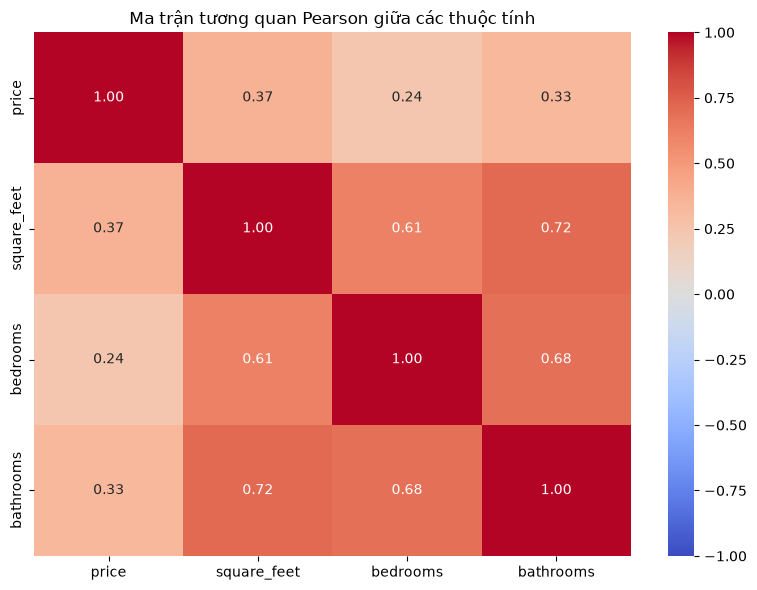

In [93]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    df_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Ma trận tương quan Pearson giữa các thuộc tính")

plt.tight_layout()
plt.show()


**Nhận xét**
- Heatmap cho thấy các hệ số tương quan giữa những thuộc tính đều mang giá trị dương, không xuất hiện cặp thuộc tính có tương quan âm
- Cặp square_feet và bathrooms có hệ số tương quan cao nhất trong các cặp biến khác nhau 0,72, tiếp theo là bedrooms và bathrooms 0,68 và square_feet và bedrooms 0,61
- Các cặp liên quan đến price có hệ số tương quan thấp hơn, dao động từ 0,24 đến 0,37, thể hiện mức độ liên hệ tuyến tính tương đối yếu với giá thuê

=> Heatmap giúp thấy rõ sự khác biệt về mức độ tương quan giữa các cặp thuộc tính. Các đặc điểm diện tích và số phòng có mối liên hệ tuyến tính với nhau cao hơn so với mối liên hệ riêng lẻ của chúng với giá thuê

**Kết luận chung**
Thông qua hệ số tương quan Pearson và Heatmap, em nhận thấy các thuộc tính price, square_feet, bedrooms và bathrooms đều có xu hướng biến động cùng chiều

Trong đó, square_feet có hệ số tương quan với price cao nhất (0,371) trong ba thuộc tính được xem xét, tiếp theo là bathrooms (0,330) và bedrooms (0,237). Tuy nhiên, các mối liên hệ này đều ở mức yếu

Ngược lại, diện tích, số phòng ngủ và số phòng tắm có tương quan khá cao với nhau, với hệ số từ 0,613 đến 0,716.

Nhìn chung, kết quả cho thấy giá thuê có thể liên quan đến nhiều đặc điểm của căn hộ

### 7.3. Hồi quy tuyến tính (Linear Regression)
Sử dụng hồi quy tuyến tính đơn để xây dựng mô hình dự đoán giá thuê căn hộ dựa trên diện tích trong bộ dữ liệu

Trong đó:
- Biến độc lập X: square_feet, diện tích căn hộ
- Biến phụ thuộc y: price, giá thuê theo tháng

Dữ liệu được chia thành tập huấn luyện (80%) và tập kiểm tra (20%)

#### Chuẩn bị và chia dữ liệu train, test

In [94]:

from sklearn.model_selection import train_test_split

df_lr = df_clean[["square_feet", "price"]].dropna()

X_lr = df_lr[["square_feet"]]
y_lr = df_lr["price"]

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr,
    test_size=0.2,
    random_state=42
)

print("Tổng số bản ghi:", len(df_lr))
print("Số bản ghi huấn luyện:", len(X_train_lr))
print("Số bản ghi kiểm tra:", len(X_test_lr))


Tổng số bản ghi: 99342
Số bản ghi huấn luyện: 79473
Số bản ghi kiểm tra: 19869


**Nhận xét**
- Bộ dữ liệu sử dụng cho hồi quy gồm 99.342 bản ghi, với hai thuộc tính square_feet (diện tích) và price (giá thuê)
- Dữ liệu được chia theo tỷ lệ 80/20, trong đó 79.473 bản ghi dùng để huấn luyện và 19.869 bản ghi dùng để kiểm tra

=> Dữ liệu đã được chuẩn bị và chia thành hai tập để phục vụ quá trình xây dựng và đánh giá mô hình hồi quy tuyến tính

#### Huấn luyện và dự đoán bằng Linear Regression

In [95]:

from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train_lr, y_train_lr)

intercept = model_lr.intercept_
coefficient = model_lr.coef_[0]

print(f"Hệ số chặn (Intercept): {intercept:.2f}")
print(f"Hệ số góc (Coefficient): {coefficient:.4f}")

print(
    f"Phương trình: price = {intercept:.2f} "
    f"+ ({coefficient:.4f} × square_feet)"
)

y_pred_lr = model_lr.predict(X_test_lr)

df_predictions_lr = pd.DataFrame({
    "Diện tích (ft^2)": X_test_lr["square_feet"].to_numpy(),
    "Giá thực tế": y_test_lr.to_numpy(),
    "Giá dự đoán": y_pred_lr
})

display(df_predictions_lr.head(10).round(2))


Hệ số chặn (Intercept): 810.76
Hệ số góc (Coefficient): 0.7469
Phương trình: price = 810.76 + (0.7469 × square_feet)


,Diện tích (ft^2),Giá thực tế,Giá dự đoán
0,731,2065.0,1356.77
1,1000,1100.0,1557.70
2,1063,1393.0,1604.76
3,761,2164.0,1379.18
4,787,945.0,1398.60
5,1420,1441.0,1871.42
6,2808,2900.0,2908.17
7,968,1320.0,1533.80
8,344,1175.0,1067.71
9,972,1135.0,1536.79


**Nhận xét**
- Sau khi huấn luyện, mô hình xác định được hệ số chặn (Intercept) = 810,76 và hệ số góc (Coefficient) = 0,7469.
- Phương trình hồi quy thu được: price = 810,76 + 0,7469 × square_feet
- Hệ số góc mang giá trị dương, cho thấy theo mô hình, khi diện tích tăng thêm 1 ft^2 thì giá thuê dự đoán tăng khoảng 0,7469 USD/tháng.
- Quan sát 10 kết quả dự đoán đầu tiên, có những bản ghi có giá dự đoán khá gần giá thực tế. Chẳng hạn, căn hộ diện tích 2.808 ft^2 có giá thực tế 2900 USD và giá dự đoán 2908,17 USD
- Một số bản ghi có sự chênh lệch đáng kể. Ví dụ, căn hộ 731 ft^2 có giá thực tế 2065 USD nhưng mô hình dự đoán 1356,77 USD

=> Mô hình đã xác định được mối liên hệ tuyến tính cùng chiều giữa diện tích và giá thuê, đồng thời có thể đưa ra giá thuê dự đoán cho các bản ghi trong tập kiểm tra. Tuy nhiên, các kết quả dự đoán vẫn có sự chênh lệch so với giá thực tế.

**Kết luận chung**
Mô hình được huấn luyện trên 79.473 bản ghi và kiểm tra trên 19.869 bản ghi. Phương trình hồi quy thu được cho thấy diện tích và giá thuê có xu hướng biến động cùng chiều, phù hợp với kết quả tương quan Pearson

Qua một số kết quả dự đoán ban đầu, giá thuê dự đoán có sự chênh lệch so với giá thực tế ở từng căn hộ. Điều này có thể do giá thuê còn liên quan đến vị trí, số phòng và các đặc điểm khác ngoài diện tích.

Nhìn chung, mô hình đã được xây dựng và thực hiện dự đoán thành công. 

### 7.4. Đánh giá mô hình hồi quy
Sử dụng các chỉ số MAE, MSE, RMSE và R^2 để đánh giá mô hình hồi quy tuyến tính dự đoán giá thuê dựa trên diện tích căn hộ.

Việc đánh giá được thực hiện trên tập kiểm tra đã chia ở mục 7.3, nhằm xem xét sai số dự đoán và mức độ phù hợp của mô hình.

#### Tính các chỉ số đánh giá mô hình

In [96]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_lr = mean_absolute_error(y_test_lr, y_pred_lr)
mse_lr = mean_squared_error(y_test_lr, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test_lr, y_pred_lr)

df_metrics_lr = pd.DataFrame({
    "Chỉ số": ["MAE", "MSE", "RMSE", "R²"],
    "Giá trị": [mae_lr, mse_lr, rmse_lr, r2_lr]
})

display(df_metrics_lr.round(4))


,Chỉ số,Giá trị
0,MAE,509.4220
1,MSE,718653.6590
2,RMSE,847.7344
3,R²,0.1686


**Nhận xét**
- MAE = 509,42 USD/tháng: Cho thấy mức sai lệch tuyệt đối trung bình giữa giá thuê dự đoán và thực tế khoảng 509,42 USD. So với giá thuê trung bình 1526,92 USD/tháng đây là mức sai số tương đối đáng kể.
- MSE = 718653,66: Thể hiện sai số bình phương trung bình khá lớn, cho thấy mô hình có những trường hợp dự đoán chênh lệch nhiều so với giá thực tế.
- RMSE = 847,73 USD/tháng: Cao hơn MAE, cho thấy các sai số lớn có ảnh hưởng đáng kể đến kết quả đánh giá.
- R^2 = 0,1686: Mô hình giải thích được khoảng 16,86% sự biến động của giá thuê trên tập kiểm tra. Phần biến động còn lại chưa được giải thích bởi mô hình chỉ sử dụng diện tích.

=> Mô hình hồi quy tuyến tính đơn có khả năng dự đoán giá thuê nhưng sai số còn tương đối lớn và R² thấp. Điều này cho thấy chỉ sử dụng diện tích chưa đủ để giải thích tốt sự khác biệt về giá thuê giữa các căn hộ

#### Biểu đồ so sánh giá thực tế và giá dự đoán
Dùng scatterplot giữa giá thực tế và giá dự đoán, có thêm đường tham chiếu thể hiện dự đoán hoàn hảo

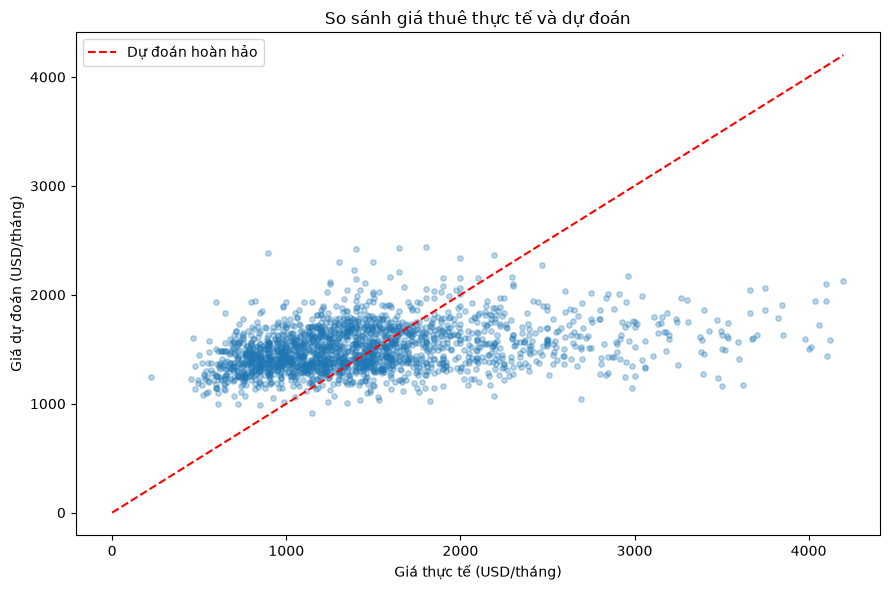

In [97]:

import matplotlib.pyplot as plt

df_eval_lr = pd.DataFrame({
    "Giá thực tế": y_test_lr.to_numpy(),
    "Giá dự đoán": y_pred_lr
})

df_visual_lr = df_eval_lr[
    (df_eval_lr["Giá thực tế"] <=
     df_eval_lr["Giá thực tế"].quantile(0.99)) &
    (df_eval_lr["Giá dự đoán"] <=
     df_eval_lr["Giá dự đoán"].quantile(0.99))
]

df_visual_lr = df_visual_lr.sample(
    n=min(2000, len(df_visual_lr)),
    random_state=42
)

plt.figure(figsize=(9, 6))

plt.scatter(
    df_visual_lr["Giá thực tế"],
    df_visual_lr["Giá dự đoán"],
    alpha=0.3,
    s=15
)

max_price = df_visual_lr[
    ["Giá thực tế", "Giá dự đoán"]
].max().max()

plt.plot(
    [0, max_price],
    [0, max_price],
    "r--",
    label="Dự đoán hoàn hảo"
)

plt.title("So sánh giá thuê thực tế và dự đoán")
plt.xlabel("Giá thực tế (USD/tháng)")
plt.ylabel("Giá dự đoán (USD/tháng)")
plt.legend()

plt.tight_layout()
plt.show()


**Nhận xét**
- Biểu đồ cho thấy các điểm dữ liệu phân bố khá xa đường tham chiếu dự đoán hoàn hảo (đường nét đứt màu đỏ), thể hiện sự chênh lệch giữa giá thuê thực tế và giá thuê dự đoán.
- Phần lớn giá dự đoán tập trung trong khoảng 1200–1800 USD/tháng, trong khi giá thực tế phân bố rộng hơn, từ vài trăm đến trên 4000 USD/tháng trong phần dữ liệu hiển thị.
- Ở những căn hộ có giá thực tế thấp, khoảng dưới 1000 USD/tháng, nhiều điểm nằm phía trên đường tham chiếu, cho thấy mô hình có xu hướng dự đoán cao hơn thực tế.
- Ngược lại, ở những căn hộ có giá thực tế từ khoảng 2000 USD/tháng trở lên, phần lớn điểm nằm dưới đường tham chiếu, cho thấy mô hình có xu hướng dự đoán thấp hơn giá thực tế.
- Các điểm dữ liệu tạo thành một dải tương đối ngang, thể hiện giá dự đoán thay đổi trong phạm vi hẹp hơn so với giá thực tế.

=> Biểu đồ cho thấy mô hình chưa dự đoán tốt ở các mức giá quá thấp hoặc quá cao

**Kết luận chung**
Mô hình hồi quy tuyến tính đơn được đánh giá trên 19.869 bản ghi thuộc tập kiểm tra, sử dụng các chỉ số MAE, MSE, RMSE và R^2.

Kết quả cho thấy mô hình có MAE khoảng 509,42 USD/tháng, RMSE khoảng 847,73 USD/tháng và R^2 đạt 0,1686, tương ứng với khả năng giải thích khoảng 16,86% sự biến động giá thuê trên tập kiểm tra.

Biểu đồ so sánh giá thực tế và dự đoán cho thấy mô hình có xu hướng dự đoán cao hơn thực tế ở những căn hộ giá thấp và thấp hơn thực tế ở những căn hộ giá cao.

Nhìn chung, mô hình đã thực hiện được việc dự đoán giá thuê dựa trên diện tích nhưng hiệu quả còn hạn chế. Nguyên nhân có thể do giá thuê còn liên quan đến vị trí, số phòng, tiện ích và những yếu tố khác chưa được đưa vào mô hình.

Kết quả cho thấy hồi quy tuyến tính đơn phù hợp để làm mô hình cơ sở, nhưng chưa đủ tốt để sử dụng như một công cụ định giá căn hộ thực tế.

## 8. Học máy có giám sát
### 8.1. Hồi quy Logistic (Logistic Regression)
Sử dụng Logistic Regression để phân loại căn hộ theo hai nhóm giá thuê, dựa trên diện tích, số phòng ngủ và số phòng tắm

Lấy mức giá thuê trung vị 1350 USD/tháng làm ngưỡng phân loại:
- Nhãn 0: Giá thuê nhỏ hơn hoặc bằng 1350 USD/tháng
- Nhãn 1: Giá thuê lớn hơn 1350 USD/tháng

Dữ liệu được chia thành tập huấn luyện (80%) và tập kiểm tra (20%)

#### Chuẩn bị dữ liệu và chia train, test

In [98]:

from sklearn.model_selection import train_test_split

df_log = df_clean[
    ["square_feet", "bedrooms", "bathrooms", "price"]
].dropna().copy()

df_log["high_rent"] = (df_log["price"] > 1350).astype(int)

X_log = df_log[["square_feet", "bedrooms", "bathrooms"]]
y_log = df_log["high_rent"]

print("Tổng số bản ghi:", len(df_log))
print("\nSố lượng theo nhóm giá thuê:")
print(y_log.value_counts().sort_index())

X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log, y_log,
    test_size=0.2,
    random_state=42,
    stratify=y_log
)

print("\nSố bản ghi Train:", len(X_train_log))
print("Số bản ghi Test:", len(X_test_log))


Tổng số bản ghi: 99158

Số lượng theo nhóm giá thuê:
high_rent
0    49704
1    49454
Name: count, dtype: int64

Số bản ghi Train: 79326
Số bản ghi Test: 19832


**Nhận xét**
- Sau khi loại bỏ các bản ghi thiếu thuộc tính cần thiết, dữ liệu sử dụng cho Logistic Regression còn 99158 bản ghi
- Dữ liệu được chia thành hai nhóm theo ngưỡng giá thuê 1350 USD/tháng. Trong đó, nhãn 0 có 49704 bản ghi, nhãn 1 có 49454 bản ghi
- Số lượng giữa hai nhóm tương đối cân bằng, mỗi nhóm chiếm khoảng 50% dữ liệu.
- Dữ liệu được chia theo tỷ lệ 80/20, gồm 79326 bản ghi huấn luyện và 19832 bản ghi kiểm tra

=> Dữ liệu đã được chuẩn bị phù hợp cho bài toán phân loại hai nhóm giá thuê, không có sự mất cân bằng đáng kể về số lượng giữa hai lớp

#### Huấn luyện và dự đoán bằng Logistic Regression
Phù hợp vì diện tích thường có trị bằng hàng trăm hoặc hàng nghìn, còn số phòng tắm và phòng ngủ có giá trị nhỏ hơn

Theo ngưỡng mặc định 0,5, nếu xác suất nhãn 1 lớn hơn 0,5, mô hình dự đoán căn hộ thuộc nhóm giá thuê trên 1350 USD/tháng

In [99]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler_log = StandardScaler()

X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

model_log = LogisticRegression(max_iter=1000)

model_log.fit(X_train_log_scaled, y_train_log)

y_pred_log = model_log.predict(X_test_log_scaled)

y_prob_log = model_log.predict_proba(X_test_log_scaled)[:, 1]

df_predictions_log = pd.DataFrame({
    "Nhãn thực tế": y_test_log.to_numpy(),
    "Nhãn dự đoán": y_pred_log,
    "Xác suất nhãn 1": y_prob_log
})

display(df_predictions_log.head(10).round(3))


,Nhãn thực tế,Nhãn dự đoán,Xác suất nhãn 1
0,1,1,0.626
1,1,1,0.620
2,1,1,0.688
3,0,0,0.399
4,0,0,0.323
5,1,1,0.510
6,0,0,0.272
7,1,0,0.350
8,1,1,0.644
9,1,0,0.471


**Nhận xét**
- Sau khi huấn luyện, mô hình Logistic Regression thực hiện phân loại các căn hộ thành hai nhóm giá thuê dựa trên diện tích, số phòng ngủ và số phòng tắm
- Trong 10 kết quả hiển thị đầu tiên, mô hình dự đoán đúng 7 bản ghi và sai 3 bản ghi
- Một số trường hợp có xác suất nhãn 1 lớn hơn 0,5 được phân loại vào nhóm giá thuê trên 1350 USD/tháng. Chẳng hạn, bản ghi thứ 2 có xác suất 0,620 và được dự đoán đúng nhãn 1
- Một số trường hợp mô hình dự đoán sai, như bản ghi đầu tiên có nhãn thực tế là 0 nhưng được dự đoán thành 1 với xác suất 0,626. Ngoài ra, các bản ghi có xác suất gần 0,5 như 0,510 hoặc 0,471 thể hiện kết quả phân loại gần ngưỡng quyết định

=> Mô hình đã thực hiện được việc dự đoán nhãn và xác suất phân loại. Tuy nhiên, vẫn có những trường hợp dự đoán sai

#### Đánh giá mô hình Logistic Regression

Accuracy: 0.6354

Classification Report:
              precision    recall  f1-score   support

           0      0.624     0.684     0.653      9941
           1      0.649     0.586     0.616      9891

    accuracy                          0.635     19832
   macro avg      0.637     0.635     0.634     19832
weighted avg      0.637     0.635     0.634     19832



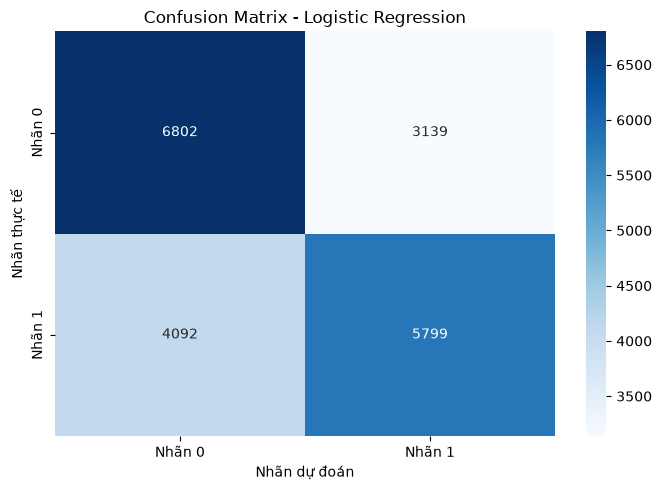

In [100]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

accuracy_log = accuracy_score(y_test_log, y_pred_log)

print(f"Accuracy: {accuracy_log:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_log,
    y_pred_log,
    digits=3,
    zero_division=0
))

cm_log = confusion_matrix(y_test_log, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Nhãn 0", "Nhãn 1"],
    yticklabels=["Nhãn 0", "Nhãn 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()


**Nhận xét**
- Accuracy = 0,6354 (63,54%), cho thấy mô hình phân loại đúng khoảng 63,54% số bản ghi trong tập kiểm tra
- Nhãn 0: Precision = 0,624, Recall = 0,684 và F1-score = 0,653. Mô hình nhận diện đúng khoảng 68,4% số căn hộ thực tế thuộc nhóm giá thuê không quá 1350 USD/tháng
- Nhãn 1: Precision = 0,649, Recall = 0,586 và F1-score = 0,616. Mô hình chỉ nhận diện đúng khoảng 58,6% số căn hộ thực tế thuộc nhóm giá thuê trên 1350 USD/tháng
- Confusion Matrix: Trong 19832 bản ghi kiểm tra, mô hình dự đoán đúng 6802 bản ghi nhãn 0 và 5799 bản ghi nhãn 1. Tuy nhiên, có 3139 bản ghi nhãn 0 bị dự đoán thành nhãn 1 và 4092 bản ghi nhãn 1 bị dự đoán thành nhãn 0
- F1-score của nhãn 0 cao hơn nhãn 1, cho thấy mô hình có khả năng nhận diện nhóm giá thuê thấp hơn hoặc bằng ngưỡng tốt hơn nhóm giá thuê trên ngưỡng

=> Mô hình đạt hiệu quả phân loại ở mức còn hạn chế. Mặc dù dữ liệu giữa hai lớp tương đối cân bằng, mô hình vẫn dự đoán sai 7231 bản ghi, đặc biệt bỏ sót khá nhiều căn hộ thuộc nhóm giá thuê trên 1350 USD/tháng

**Kết luận chung**
Mô hình được huấn luyện trên 79326 bản ghi và đánh giá trên 19832 bản ghi, đạt Accuracy 63,54% và F1-score trung bình theo lớp (Macro Average) khoảng 0,634.

Kết quả Confusion Matrix cho thấy mô hình nhận diện nhóm giá thuê thấp hơn hoặc bằng 1350 USD/tháng tốt hơn nhóm giá thuê trên 1350 USD/tháng. Tuy nhiên, số lượng dự đoán sai vẫn còn khá lớn.

Nhìn chung, Logistic Regression đã thực hiện được bài toán phân loại hai nhóm giá thuê, nhưng hiệu quả chưa cao. Điều này có thể do giá thuê còn liên quan đến vị trí, tiện ích và nhiều đặc điểm khác chưa được sử dụng trong mô hình.

### 8.2. Phân loại Naive Bayes
Sử dụng thuật toán Naive Bayes để phân loại căn hộ thành hai nhóm giá thuê dựa trên diện tích, số phòng ngủ và số phòng tắm.

Mô hình sử dụng cùng dữ liệu huấn luyện và kiểm tra đã chuẩn bị ở mục 8.1, nhằm so sánh hiệu quả phân loại với Logistic Regression.

#### Huấn luyện và dự đoán bằng Naive Bayes

In [101]:

from sklearn.naive_bayes import GaussianNB

model_nb = GaussianNB()

model_nb.fit(X_train_log_scaled, y_train_log)

y_pred_nb = model_nb.predict(X_test_log_scaled)

y_prob_nb = model_nb.predict_proba(X_test_log_scaled)[:, 1]

df_predictions_nb = pd.DataFrame({
    "Nhãn thực tế": y_test_log.to_numpy(),
    "Nhãn dự đoán": y_pred_nb,
    "Xác suất nhãn 1": y_prob_nb
})

display(df_predictions_nb.head(10).round(3))


,Nhãn thực tế,Nhãn dự đoán,Xác suất nhãn 1
0,1,1,0.659
1,1,1,0.649
2,1,1,0.768
3,0,0,0.236
4,0,0,0.226
5,1,1,0.716
6,0,0,0.335
7,1,0,0.166
8,1,1,0.922
9,1,0,0.175


**Nhận xét**
- Mô hình Naive Bayes được huấn luyện trên các thuộc tính square_feet, bedrooms và bathrooms, sử dụng cùng tập dữ liệu với Logistic Regression
- Trong 10 kết quả dự đoán đầu tiên, mô hình dự đoán đúng 7 bản ghi và sai 3 bản ghi
- Một số trường hợp có xác suất nhãn 1 khá cao và được dự đoán đúng, chẳng hạn bản ghi thứ 9 có xác suất 0,922 và được phân loại đúng vào nhãn 1
- Vẫn xuất hiện các trường hợp dự đoán sai. Ví dụ, bản ghi đầu tiên có nhãn thực tế là 0 nhưng được dự đoán thành nhãn 1 với xác suất 0,659
- Hai bản ghi thứ 8 và thứ 10 có nhãn thực tế là 1 nhưng bị dự đoán thành nhãn 0, với xác suất nhãn 1 lần lượt là 0,166 và 0,175

=> Naive Bayes đã thực hiện được việc phân loại và dự đoán xác suất thuộc nhóm giá thuê trên 1.350 USD/tháng. Tuy nhiên, kết quả vẫn có những trường hợp nhầm lẫn giữa hai nhóm

#### Đánh giá Naive Bayes và so sánh với Logistic Regression
Tính Accuracy, Classification Report và Confusion Matrix tương tự 8.1. Đồng thời thêm bảng so sánh Accuracy và F1-macro của hai thuật toán.

Bảng so sánh sẽ giúp xác định mô hình nào có Accuracy và F1-macro cao hơn trên cùng tập Test.

Việc bổ sung F1-macro là để so sánh cân bằng hơn giữa hai lớp, không chỉ dựa vào Accuracy.

Accuracy Naive Bayes: 0.6323

Classification Report:
              precision    recall  f1-score   support

           0      0.615     0.711     0.660      9941
           1      0.656     0.553     0.600      9891

    accuracy                          0.632     19832
   macro avg      0.636     0.632     0.630     19832
weighted avg      0.635     0.632     0.630     19832


So sánh hai mô hình:


,Mô hình,Accuracy,F1-macro
0,Logistic Regression,0.6354,0.6345
1,Naive Bayes,0.6323,0.6298


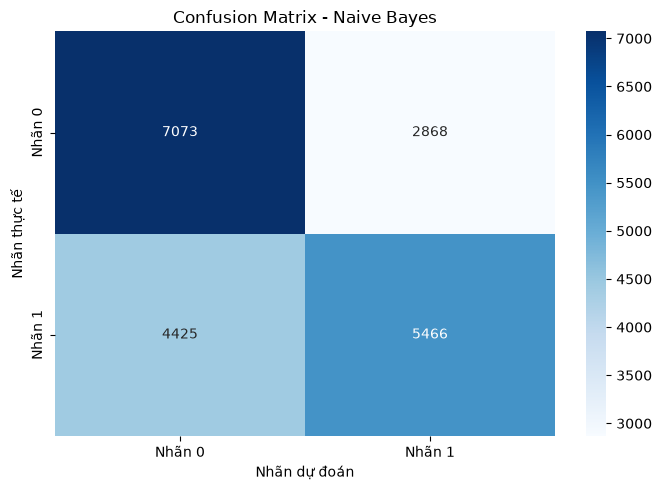

In [102]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

accuracy_nb = accuracy_score(y_test_log, y_pred_nb)
f1_nb = f1_score(y_test_log, y_pred_nb, average="macro")

print(f"Accuracy Naive Bayes: {accuracy_nb:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_log,
    y_pred_nb,
    digits=3,
    zero_division=0
))

accuracy_log = accuracy_score(y_test_log, y_pred_log)
f1_log = f1_score(y_test_log, y_pred_log, average="macro")

df_compare_models = pd.DataFrame({
    "Mô hình": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [accuracy_log, accuracy_nb],
    "F1-macro": [f1_log, f1_nb]
})

print("\nSo sánh hai mô hình:")
display(df_compare_models.round(4))

cm_nb = confusion_matrix(y_test_log, y_pred_nb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Nhãn 0", "Nhãn 1"],
    yticklabels=["Nhãn 0", "Nhãn 1"]
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()


**Nhận xét** 
- Accuracy = 0,6323 (63,23%), cho thấy mô hình Naive Bayes phân loại đúng khoảng 63,23% số bản ghi trong tập kiểm tra
- Nhãn 0: Precision = 0,615, Recall = 0,711 và F1-score = 0,660. Mô hình nhận diện đúng khoảng 71,1% số căn hộ thực tế có giá thuê không quá 1350 USD/tháng
- Nhãn 1: Precision = 0,656, Recall = 0,553 và F1-score = 0,600. Mô hình nhận diện đúng khoảng 55,3% số căn hộ thực tế có giá thuê trên 1350 USD/tháng
- Confusion Matrix: Trong 19832 bản ghi kiểm tra, mô hình dự đoán đúng 7073 bản ghi nhãn 0 và 5466 bản ghi nhãn 1. Ngoài ra, có 2868 bản ghi nhãn 0 bị dự đoán thành nhãn 1 và 4425 bản ghi nhãn 1 bị dự đoán thành nhãn 0
- So sánh hai mô hình: Logistic Regression đạt Accuracy 63,54% và F1-macro 0,6345, cao hơn Naive Bayes với Accuracy 63,23% và F1-macro 0,6298

=> Naive Bayes có hiệu quả phân loại thấp hơn Logistic Regression một chút. Mô hình nhận diện nhãn 0 tốt hơn, nhưng bỏ sót nhiều căn hộ thuộc nhãn 1. Cả hai mô hình vẫn còn hạn chế khi chỉ sử dụng ba thuộc tính để phân loại nhóm giá thuê



**Kết luận chung**
Mô hình được đánh giá trên 19832 bản ghi thuộc tập kiểm tra, đạt Accuracy 63,23% và F1-macro 0,6298. Kết quả Confusion Matrix cho thấy mô hình có khả năng nhận diện nhóm giá thuê thấp hơn hoặc bằng 1350 USD/tháng tốt hơn nhóm giá thuê trên ngưỡng.

Khi so sánh với Logistic Regression, Naive Bayes có hiệu quả thấp hơn một chút về Accuracy và F1-macro. Tuy nhiên, mức chênh lệch giữa hai mô hình không lớn.

Nhìn chung, cả hai thuật toán đều thực hiện được bài toán phân loại nhóm giá thuê, nhưng khả năng dự đoán còn hạn chế. Nguyên nhân có thể do các thuộc tính đầu vào chưa phản ánh đầy đủ những yếu tố liên quan đến giá thuê, đồng thời một số giả định của Naive Bayes có thể chưa phù hợp hoàn toàn với dữ liệu

## 9. Phân cụm và luật kết hợp
### 9.1. Phân cụm K-Means
Sử dụng thuật toán K-Means để phân nhóm các tin đăng căn hộ dựa trên hai thuộc tính price và square_feet.

Các bước thực hiện gồm chuẩn bị dữ liệu, lựa chọn số cụm K bằng phương pháp Elbow, huấn luyện K-Means và trực quan hóa kết quả phân cụm.

#### Chuẩn bị và chuẩn hóa dữ liệu
Bước chuẩn hóa giúp khoảng cách Euclidean không bị chi phối chỉ vì các thuộc tính sử dụng thang đo khác nhau

In [103]:

from sklearn.preprocessing import StandardScaler

df_kmeans = df_clean[["price", "square_feet"]].dropna().copy()

rows_before = len(df_kmeans)

price_p99 = df_kmeans["price"].quantile(0.99)
area_p99 = df_kmeans["square_feet"].quantile(0.99)

df_kmeans = df_kmeans[
    (df_kmeans["price"] <= price_p99) &
    (df_kmeans["square_feet"] <= area_p99)
].copy()

print("Số bản ghi ban đầu:", rows_before)
print("Số bản ghi được giữ lại:", len(df_kmeans))
print("Số bản ghi ngoài phạm vi phân tích:",
      rows_before - len(df_kmeans))

scaler_kmeans = StandardScaler()
X_kmeans = scaler_kmeans.fit_transform(
    df_kmeans[["price", "square_feet"]]
)

print("Kích thước dữ liệu sau chuẩn hóa:", X_kmeans.shape)


Số bản ghi ban đầu: 99342
Số bản ghi được giữ lại: 97568
Số bản ghi ngoài phạm vi phân tích: 1774
Kích thước dữ liệu sau chuẩn hóa: (97568, 2)


**Nhận xét**
- Dữ liệu ban đầu gồm 99342 bản ghi. Sau khi giới hạn giá thuê và diện tích ở phân vị 99%, có 1774 bản ghi nằm ngoài phạm vi phân tích và 97568 bản ghi được giữ lại
- Dữ liệu phân cụm sử dụng hai thuộc tính price và square_feet, tương ứng với giá thuê và diện tích căn hộ
- Chuẩn hóa bằng StandardScaler, dữ liệu có kích thước (97568, 2), gồm 97568 bản ghi và 2 đặc trưng
- Việc chuẩn hóa giúp giảm ảnh hưởng của sự khác biệt về thang đo giữa giá thuê và diện tích khi K-Means tính khoảng cách

=> Dữ liệu đã được chuẩn bị để thực hiện phân cụm K-Means

#### Xác định số cụm bằng phương pháp Elbow
Xem mức độ giảm của tổng bình phương khoảng cách trong cụm khi cụm K tăng


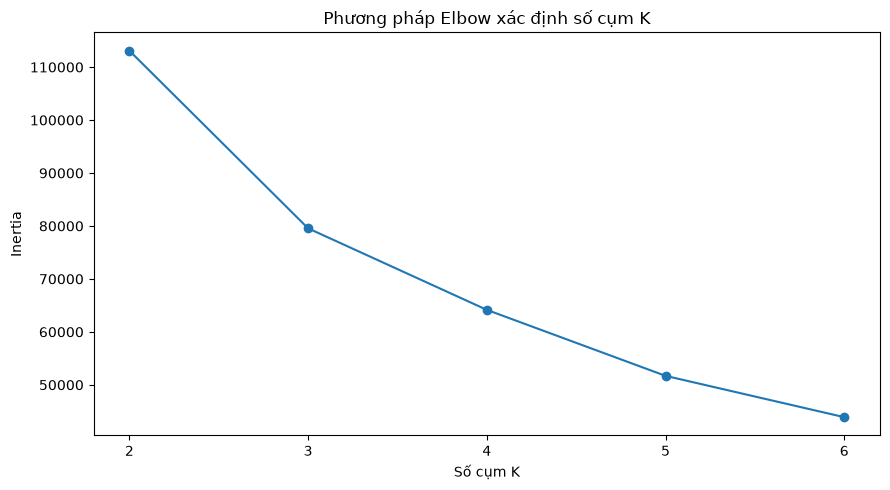

In [104]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = range(2, 7)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_kmeans)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.title("Phương pháp Elbow xác định số cụm K")
plt.xlabel("Số cụm K")
plt.ylabel("Inertia")
plt.xticks(list(k_values))

plt.tight_layout()
plt.show()


**Nhận xét**
- Biểu đồ Elbow cho thấy Inertia giảm liên tục khi số cụm K tăng từ 2 đến 6
- Khi K tăng từ 2 lên 3, Inertia giảm khá mạnh, từ khoảng 113000 xuống 79000
- K = 3 trở đi, Inertia vẫn tiếp tục giảm nhưng mức giảm giữa các lần tăng K nhìn chung nhỏ hơn so với giai đoạn K = 2 đến K = 3
- Đường cong có sự thay đổi độ dốc đáng chú ý tại khoảng K = 3, vì vậy có thể lựa chọn 3 cụm để tiếp tục thực hiện K-Means

=> Phương pháp Elbow hỗ trợ lựa chọn K = 3 cho bài toán phân nhóm căn hộ theo giá thuê và diện tích

#### Huấn luyện K means và trực quan hóa các cụm
Tạm chọn K = 3 để minh họa

Đặc điểm của các cụm:


,so_tin,gia_thue_tb,dien_tich_tb
cluster,,,
0,52154,1145.14,741.80
1,30325,1454.14,1209.32
2,15089,2636.45,1027.57


Tâm của các cụm:


,price,square_feet
0,1145.36,742.19
1,1455.71,1209.81
2,2638.54,1027.27


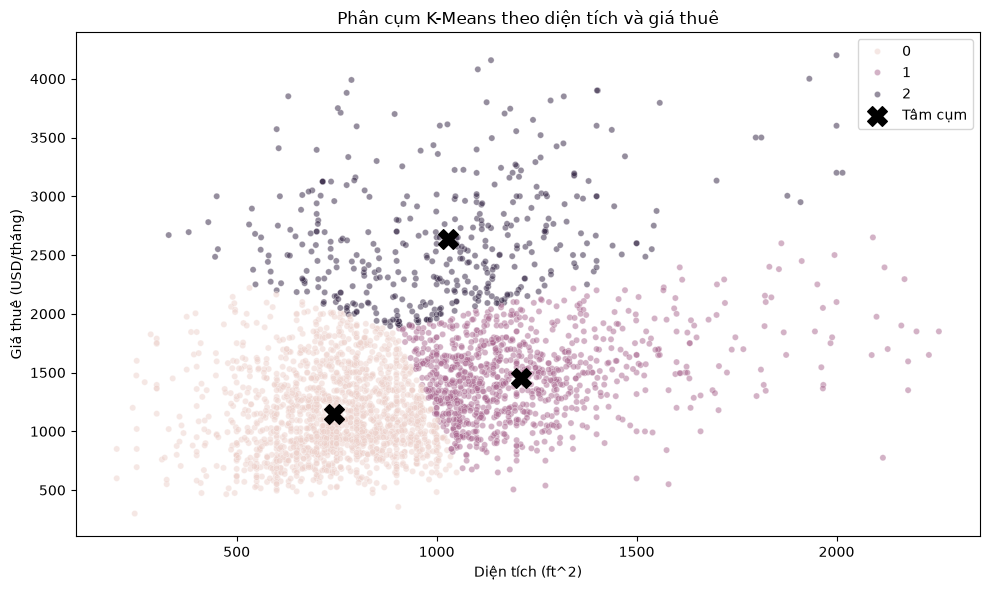

In [106]:

import seaborn as sns

k_selected = 3

model_kmeans = KMeans(
    n_clusters=k_selected,
    random_state=42,
    n_init=10
)

df_kmeans["cluster"] = model_kmeans.fit_predict(X_kmeans)

df_cluster_summary = df_kmeans.groupby("cluster").agg(
    so_tin=("price", "size"),
    gia_thue_tb=("price", "mean"),
    dien_tich_tb=("square_feet", "mean")
)

print("Đặc điểm của các cụm:")
display(df_cluster_summary.round(2))

centers = scaler_kmeans.inverse_transform(
    model_kmeans.cluster_centers_
)

df_centers = pd.DataFrame(
    centers,
    columns=["price", "square_feet"]
)

print("Tâm của các cụm:")
display(df_centers.round(2))

df_kmeans_plot = df_kmeans.sample(
    n=min(3000, len(df_kmeans)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_kmeans_plot,
    x="square_feet",
    y="price",
    hue="cluster",
    alpha=0.5,
    s=20
)

plt.scatter(
    centers[:, 1],
    centers[:, 0],
    marker="X",
    s=200,
    color="black",
    label="Tâm cụm"
)

plt.title("Phân cụm K-Means theo diện tích và giá thuê")
plt.xlabel("Diện tích (ft^2)")
plt.ylabel("Giá thuê (USD/tháng)")
plt.legend()

plt.tight_layout()
plt.show()


**Nhận xét**
- Cụm 0: Có 52154 tin đăng, chiếm khoảng 53,5% dữ liệu phân cụm. Giá thuê trung bình khoảng 1145,14 USD/tháng và diện tích trung bình 741,80 ft^2. Đây là nhóm có giá thuê và diện tích trung bình thấp nhất trong ba cụm
- Cụm 1: Có 30325 tin đăng, chiếm khoảng 31,1%. Giá thuê trung bình 1454,14 USD/tháng và diện tích trung bình 1.209,32 ft^2. Đây là nhóm có diện tích trung bình lớn nhất, nhưng giá thuê không cao nhất
- Cụm 2: Có 15089 tin đăng, chiếm khoảng 15,5%. Giá thuê trung bình 2636,45 USD/tháng và diện tích trung bình 1027,57 ft^2. Đây là nhóm có giá thuê trung bình cao nhất, dù diện tích trung bình nhỏ hơn cụm 1
- Các tâm cụm có tọa độ tương ứng gần với giá thuê và diện tích trung bình của từng nhóm
- Trên Scatterplot, các cụm được phân biệt bằng màu sắc và dấu X thể hiện vị trí tâm cụm. Có thể quan sát sự khác biệt về phân bố giá thuê và diện tích giữa ba nhóm, mặc dù các cụm vẫn có những vùng giá trị nằm gần nhau

=> K-Means đã chia các tin đăng thành ba nhóm có đặc điểm khác nhau: nhóm giá thuê và diện tích thấp, nhóm diện tích lớn với giá thuê trung bình, và nhóm giá thuê cao. Kết quả cũng cho thấy diện tích lớn hơn không phải lúc nào cũng đi kèm với giá thuê cao hơn

**Ketses luận chung**
Thông qua thuật toán K-Means, em đã thực hiện phân cụm 97568 tin đăng dựa trên hai thuộc tính giá thuê và diện tích.

Phương pháp Elbow được sử dụng để hỗ trợ lựa chọn K = 3. Kết quả phân cụm cho thấy:

- Cụm 0: Nhóm căn hộ có giá thuê và diện tích trung bình thấp.

- Cụm 1: Nhóm căn hộ có diện tích trung bình lớn nhất, giá thuê ở mức trung bình.

- Cụm 2: Nhóm căn hộ có giá thuê trung bình cao nhất.

Trong ba cụm, cụm 0 có số lượng tin đăng lớn nhất, chiếm khoảng 53,5%, trong khi cụm 2 có số lượng ít nhất, khoảng 15,5%.

Nhìn chung, K-Means giúp phân nhóm các căn hộ theo đặc điểm tương đồng về giá thuê và diện tích

### 9.2. Luật kết hợp (Association Rules)
Sử dụng thuật toán Apriori để tìm các tiện ích thường xuất hiện cùng nhau trong tin

Mỗi tin đăng có thông tin tiện ích được xem là một giao dịch, trong đó các tiện ích là các mục dữ liệu



#### Chuẩn bị dữ liệu giao dịch

In [109]:
amenities_data = df_clean["amenities"].dropna().astype(str)

transactions_ar = amenities_data.apply(
    lambda x: sorted(set(
        item.strip()
        for item in x.split(",")
        if item.strip()
    ))
)

transactions_ar = transactions_ar[
    transactions_ar.apply(len) > 0
]

print("Số giao dịch hợp lệ:", len(transactions_ar))

df_transactions_ar = pd.DataFrame({
    "Tiện ích": transactions_ar.head(5).apply(", ".join)
})

display(df_transactions_ar)


Số giao dịch hợp lệ: 83310


,Tiện ích
21,"Fireplace, Gym, Parking, Pool, Storage, Wood F..."
22,"Gated, Pool"
23,"Dishwasher, Parking, Pool"
24,"Dishwasher, Parking, Pool"
25,"Gym, Pool"


**Nhận xét**
- Sau khi loại bỏ các bản ghi thiếu hoặc không có thông tin tiện ích, dữ liệu còn 83310 giao dịch hợp lệ để phân tích luật kết hợp
- Mỗi giao dịch tương ứng với một tin đăng căn hộ, chứa danh sách các tiện ích được ghi nhận như Gym, Parking, Pool, Dishwasher và Storage
- Quan sát 5 giao dịch đầu tiên cho thấy số lượng và loại tiện ích có sự khác nhau giữa các tin đăng. Một số tin đăng chỉ có 2 tiện ích, trong khi những tin đăng khác có nhiều tiện ích hơn
- Một số tiện ích như Parking và Pool xuất hiện cùng nhau trong nhiều giao dịch mẫu.

=> Thuộc tính amenities đã được chuyển thành dữ liệu giao dịch

#### Tìm tập mục phổ biến bằng Apriori
Chọn:
- Minimum Support = 0,05 (5%).
- Xét các tập mục có tối đa 3 tiện ích



In [110]:

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori

encoder_ar = TransactionEncoder()

encoded_ar = encoder_ar.fit(
    transactions_ar.tolist()
).transform(
    transactions_ar.tolist()
)

df_basket_ar = pd.DataFrame(
    encoded_ar,
    columns=encoder_ar.columns_
)

print("Kích thước bảng giao dịch:", df_basket_ar.shape)

frequent_itemsets_ar = apriori(
    df_basket_ar,
    min_support=0.05,
    use_colnames=True,
    max_len=3
)

print("Số tập mục phổ biến:", len(frequent_itemsets_ar))

df_frequent_view = frequent_itemsets_ar.sort_values(
    by="support",
    ascending=False
).head(15).copy()

df_frequent_view["itemsets"] = df_frequent_view[
    "itemsets"
].apply(lambda x: ", ".join(sorted(x)))

display(df_frequent_view.round(4))


Kích thước bảng giao dịch: (83310, 27)
Số tập mục phổ biến: 246


,support,itemsets
9,0.5248,Parking
12,0.5210,Pool
7,0.4465,Gym
75,0.3401,"Gym, Pool"
10,0.3177,Patio/Deck
17,0.3112,Washer Dryer
14,0.2589,Storage
87,0.2515,"Parking, Pool"
2,0.2287,Clubhouse
72,0.2130,"Gym, Parking"


**Nhận xét**
- Sau khi chuyển đổi dữ liệu, bảng giao dịch có kích thước (83310, 27), tương ứng với 83310 giao dịch và 27 loại tiện ích
- Với ngưỡng Support tối thiểu 0,05, thuật toán Apriori tìm được 246 tập mục phổ biến.
- Trong các tiện ích riêng lẻ, Parking có Support cao nhất (52,48%), tiếp theo là Pool (52,10%) và Gym (44,65%). Điều này cho thấy các tiện ích này được ghi nhận khá phổ biến trong dữ liệu
- Đối với các tập mục gồm hai tiện ích, Gym, Pool có Support 34,01%, Parking, Pool đạt 25,15% và Gym, Parking đạt 21,30%
- Một số tiện ích khác như Patio/Deck (31,77%), Washer Dryer (31,12%) và Storage (25,89%) cũng xuất hiện tương đối thường xuyên

=> Kết quả Apriori cho thấy các tiện ích Parking, Pool và Gym khá phổ biến trong các tin đăng căn hộ. Đặc biệt, cặp Gym, Pool xuất hiện cùng nhau trong khoảng 34% giao dịch hợp lệ, cho thấy đây là một nhóm tiện ích đáng chú ý 

#### Sinh luật kết hợp vá đánh giá Support, Confidence, Lift
Từ các tập mục phổ biến đã tìm được, xây dựng các luật A->B

Chọn:
- Minimum Confidence = 0,60 (60%)
- Chỉ giữ những luật có Lift > 1
- Sắp xếp theo Lift giảm dần để quan sát các luật nổi bật

In [111]:

from mlxtend.frequent_patterns import association_rules
import inspect

rule_params = {
    "metric": "confidence",
    "min_threshold": 0.60
}

if "num_itemsets" in inspect.signature(association_rules).parameters:
    rule_params["num_itemsets"] = len(df_basket_ar)

rules_ar = association_rules(
    frequent_itemsets_ar,
    **rule_params
)

rules_ar = rules_ar[rules_ar["lift"] > 1].copy()

rules_ar = rules_ar.sort_values(
    by=["lift", "confidence"],
    ascending=False
)

print("Số luật kết hợp tìm được:", len(rules_ar))

df_rules_view = rules_ar[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10).copy()

df_rules_view["antecedents"] = df_rules_view[
    "antecedents"
].apply(lambda x: ", ".join(sorted(x)))

df_rules_view["consequents"] = df_rules_view[
    "consequents"
].apply(lambda x: ", ".join(sorted(x)))

display(df_rules_view.round(4))


Số luật kết hợp tìm được: 243


,antecedents,consequents,support,confidence,lift
86,"Cable or Satellite, Dishwasher",Refrigerator,0.0719,0.8116,4.5414
148,"Dishwasher, Internet Access",Refrigerator,0.0503,0.8091,4.5276
149,"Internet Access, Refrigerator",Dishwasher,0.0503,0.8809,4.4277
120,"Clubhouse, Refrigerator",Dishwasher,0.0560,0.8806,4.4264
87,"Cable or Satellite, Refrigerator",Dishwasher,0.0719,0.8806,4.4262
161,"Patio/Deck, Refrigerator",Dishwasher,0.0846,0.8647,4.3464
51,"AC, Refrigerator",Dishwasher,0.0745,0.8598,4.3218
119,"Clubhouse, Dishwasher",Refrigerator,0.0560,0.7647,4.2789
144,"Gym, Refrigerator",Dishwasher,0.0683,0.8500,4.2725
166,"Pool, Refrigerator",Dishwasher,0.0823,0.8420,4.2325


**Nhận xét**
- Với ngưỡng Confidence tối thiểu 0,60 và Lift lớn hơn 1, thuật toán tìm được 243 luật kết hợp.
- Luật Cable or Satellite, Dishwasher → Refrigerator có Support 7,19%, Confidence 81,16% và Lift 4,5414. Điều này cho thấy trong các tin đăng có đồng thời Cable or Satellite và Dishwasher, khoảng 81,16% cũng ghi nhận Refrigerator.
- Luật Dishwasher, Internet Access → Refrigerator có Support 5,03%, Confidence 80,91% và Lift 4,5276, thể hiện sự xuất hiện cùng nhau tương đối cao giữa các tiện ích này.
- Luật Internet Access, Refrigerator → Dishwasher có Confidence 88,09% và Lift 4,4277, cho thấy phần lớn các tin đăng có hai tiện ích ở vế trái cũng ghi nhận Dishwasher.
- Ngoài ra, các luật Patio/Deck, Refrigerator → Dishwasher và AC, Refrigerator → Dishwasher có Confidence lần lượt 86,47% và 85,98%.
- Các luật được hiển thị đều có Lift lớn hơn 4, cho thấy những nhóm tiện ích này xuất hiện cùng nhau nhiều hơn mức kỳ vọng nếu chúng độc lập

=>  Kết quả luật kết hợp cho thấy Dishwasher và Refrigerator thường xuất hiện trong các luật có Lift cao, kết hợp với nhiều tiện ích khác. Các luật này giúp phát hiện sự liên hệ giữa những tiện ích được ghi nhận trong tin đăng căn hộ

**Kết luận chung**
Với ngưỡng Support tối thiểu 5%, thuật toán tìm được 246 tập mục phổ biến. Trong đó, Parking, Pool và Gym là những tiện ích xuất hiện thường xuyên, còn cặp Gym, Pool có Support đạt 34,01%.

Sau khi áp dụng ngưỡng Confidence tối thiểu 60% và Lift lớn hơn 1, thuật toán tìm được 243 luật kết hợp. Một số luật liên quan đến Dishwasher và Refrigerator có Confidence cao và Lift lớn hơn 4, thể hiện mức độ liên hệ đáng chú ý giữa các tiện ích.

Nhìn chung, phương pháp Apriori giúp xác định những tiện ích thường xuất hiện cùng nhau trong các tin đăng căn hộ, bổ sung cho kết quả phân cụm K-Means

## 10. Cây quyết định và PCA
### 10.1. Cây quyết định (Decision Tree)
Sử dụng thuật toán Decision Tree để phân loại căn hộ thành hai nhóm giá thuê dựa trên diện tích, số phòng ngủ và số phòng tắm.

Mô hình sử dụng cùng dữ liệu Train/Test đã chuẩn bị ở phần 8 nhằm so sánh kết quả với Logistic Regression và Naive Bayes.

Thuật toán sử dụng chỉ số Gini để lựa chọn thuộc tính và ngưỡng phân nhánh, đồng thời giới hạn độ sâu của cây để hạn chế overfitting.

#### Huấn luyện và dự đoán bàng Decision Tree

In [ ]:

from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=100,
    random_state=42
)

model_dt.fit(X_train_log, y_train_log)

y_pred_dt = model_dt.predict(X_test_log)

print("Độ sâu của cây:", model_dt.get_depth())
print("Số nút lá:", model_dt.get_n_leaves())

df_predictions_dt = pd.DataFrame({
    "Nhãn thực tế": y_test_log.to_numpy(),
    "Nhãn dự đoán": y_pred_dt
})

display(df_predictions_dt.head(10))


Độ sâu của cây: 3
Số nút lá: 8


,Nhãn thực tế,Nhãn dự đoán
0,1,1
1,1,1
2,1,1
3,0,0
4,0,0
5,1,1
6,0,0
7,1,0
8,1,1
9,1,0


**Nhận xét**
- Mô hình Decision Tree được xây dựng với tiêu chí Gini, có độ sâu thực tế bằng 3 và 8 nút lá, đúng với giới hạn đã thiết lập.
- Việc giới hạn độ sâu giúp cây không phát triển quá phức tạp, đồng thời giữ cấu trúc dễ quan sát và giải thích.
- Trong 10 kết quả dự đoán đầu tiên, mô hình dự đoán đúng 7 bản ghi và sai 3 bản ghi.
- Các trường hợp dự đoán sai gồm bản ghi đầu tiên có nhãn thực tế là 0 nhưng được dự đoán thành 1, cùng hai bản ghi có nhãn thực tế là 1 nhưng được dự đoán thành 0.

=> Mô hình đã được huấn luyện và thực hiện phân loại hai nhóm giá thuê.

#### Trực quan hóa DT và luật if then
Quy tắc tiêu biểu
- Quy tắc 1 – Dự đoán nhãn 0

IF square_feet ≤ 688.5 AND bedrooms ≤ 1.5 THEN class = 0
- Quy tắc 2 – Dự đoán nhãn 1
IF square_feet > 1277.5 AND square_feet > 1606.5 THEN class = 1

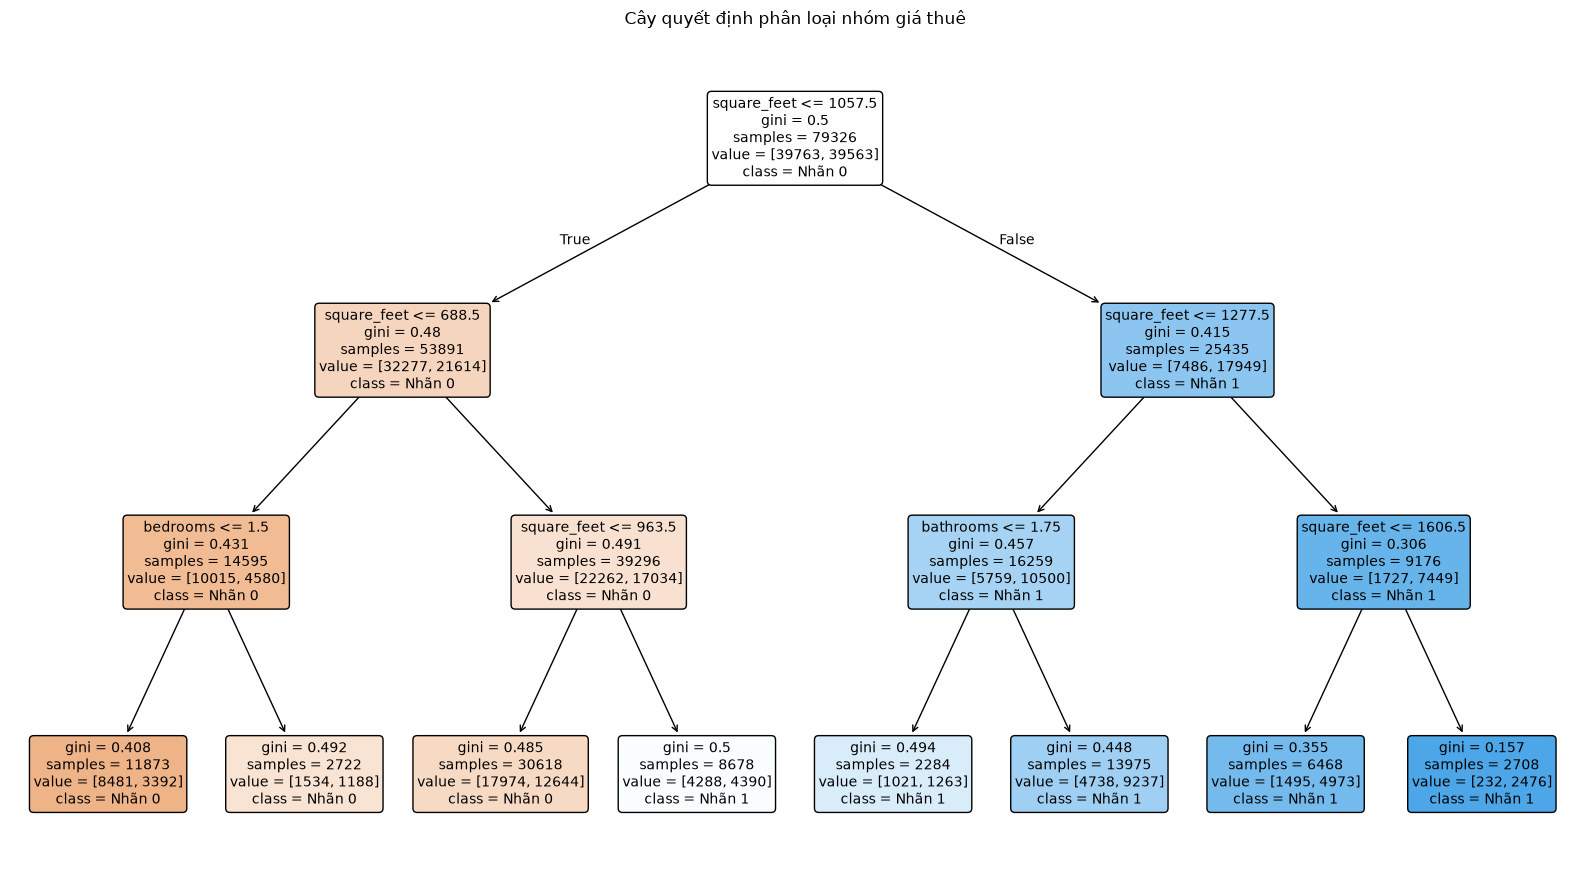

Các quy tắc của cây quyết định:
|--- square_feet <= 1057.50
|   |--- square_feet <= 688.50
|   |   |--- bedrooms <= 1.50
|   |   |   |--- class: 0
|   |   |--- bedrooms >  1.50
|   |   |   |--- class: 0
|   |--- square_feet >  688.50
|   |   |--- square_feet <= 963.50
|   |   |   |--- class: 0
|   |   |--- square_feet >  963.50
|   |   |   |--- class: 1
|--- square_feet >  1057.50
|   |--- square_feet <= 1277.50
|   |   |--- bathrooms <= 1.75
|   |   |   |--- class: 1
|   |   |--- bathrooms >  1.75
|   |   |   |--- class: 1
|   |--- square_feet >  1277.50
|   |   |--- square_feet <= 1606.50
|   |   |   |--- class: 1
|   |   |--- square_feet >  1606.50
|   |   |   |--- class: 1



In [ ]:

from sklearn.tree import plot_tree, export_text
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 9))

plot_tree(
    model_dt,
    feature_names=X_train_log.columns,
    class_names=["Nhãn 0", "Nhãn 1"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Cây quyết định phân loại nhóm giá thuê")
plt.tight_layout()
plt.show()

print("Các quy tắc của cây quyết định:")

tree_rules = export_text(
    model_dt,
    feature_names=list(X_train_log.columns),
    decimals=2
)

print(tree_rules)


**Nhận xét**
- Nút gốc của cây sử dụng thuộc tính square_feet với điều kiện diện tích ≤ 1057,5 ft^2 để phân chia dữ liệu. Điều này cho thấy diện tích là thuộc tính được chọn đầu tiên trong quá trình phân loại.
- Tại nút gốc, Gini = 0,5, với 79326 bản ghi được phân bố gần như cân bằng giữa hai nhãn.
- Ở nhánh diện tích ≤ 1057,5 ft^2, cây tiếp tục chia theo các ngưỡng 688,5 ft^2 và 963,5 ft^2. Phần lớn các nút lá trong nhánh này dự đoán nhãn 0, tương ứng với nhóm giá thuê không quá 1350 USD/tháng.
- Ở nhánh diện tích > 1057,5 ft^2, cây tiếp tục xét diện tích và số phòng tắm. Các nút lá chủ yếu dự đoán nhãn 1, tương ứng với nhóm giá thuê trên 1350 USD/tháng.
- Các quy tắc if then cho thấy những căn hộ có diện tích lớn thường được cây phân loại vào nhóm giá thuê cao hơn. Tuy nhiên, vẫn có những trường hợp diện tích nhỏ nhưng được dự đoán thuộc nhãn 1.
- Một số nút lá có Gini tương đối cao, cho thấy dữ liệu tại những nút này vẫn còn sự pha trộn giữa hai lớp.

=> Biểu đồ cho thấy square_feet đóng vai trò chính trong quá trình phân nhánh. Hai thuộc tính bedrooms và bathrooms chỉ xuất hiện ở một số nhánh, giúp bổ sung điều kiện phân loại

#### Đánh giá và so sánh DT với các mô hình trước

Train Accuracy: 0.6344
Test Accuracy: 0.6370

Classification Report:
              precision    recall  f1-score   support

           0      0.621     0.707     0.661      9941
           1      0.658     0.567     0.609      9891

    accuracy                          0.637     19832
   macro avg      0.640     0.637     0.635     19832
weighted avg      0.640     0.637     0.635     19832


So sánh các mô hình:


,Mô hình,Accuracy,F1-macro
0,Logistic Regression,0.6354,0.6345
1,Naive Bayes,0.6323,0.6298
2,Decision Tree,0.6370,0.6351


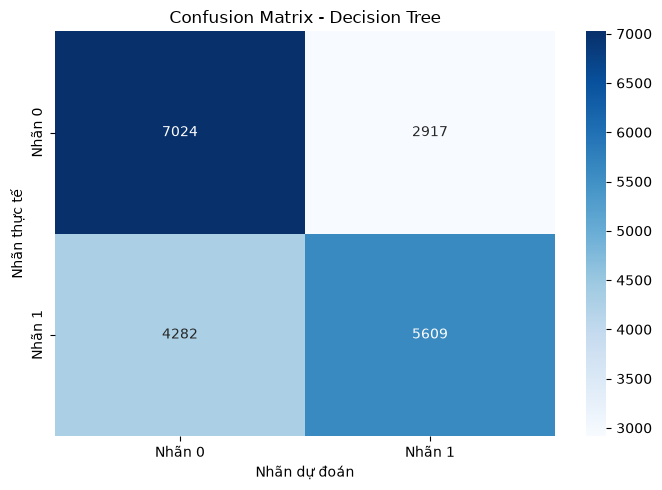

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

train_accuracy_dt = accuracy_score(
    y_train_log,
    model_dt.predict(X_train_log)
)

accuracy_dt = accuracy_score(y_test_log, y_pred_dt)
f1_dt = f1_score(y_test_log, y_pred_dt, average="macro")

print(f"Train Accuracy: {train_accuracy_dt:.4f}")
print(f"Test Accuracy: {accuracy_dt:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_log,
    y_pred_dt,
    digits=3,
    zero_division=0
))

df_compare_dt = pd.DataFrame({
    "Mô hình": [
        "Logistic Regression",
        "Naive Bayes",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test_log, y_pred_log),
        accuracy_score(y_test_log, y_pred_nb),
        accuracy_dt
    ],
    "F1-macro": [
        f1_score(y_test_log, y_pred_log, average="macro"),
        f1_score(y_test_log, y_pred_nb, average="macro"),
        f1_dt
    ]
})

print("\nSo sánh các mô hình:")
display(df_compare_dt.round(4))

cm_dt = confusion_matrix(y_test_log, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Nhãn 0", "Nhãn 1"],
    yticklabels=["Nhãn 0", "Nhãn 1"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()


**Nhận xét**
- Train Accuracy = 63,44% và Test Accuracy = 63,70%. Hai giá trị khá gần nhau, cho thấy chưa có dấu hiệu overfitting rõ rệt thông qua sự chênh lệch Accuracy trên Train và Test.
- Nhãn 0: Precision = 0,621, Recall = 0,707 và F1-score = 0,661. Mô hình nhận diện đúng khoảng 70,7% số căn hộ thực tế có giá thuê không quá 1350 USD/tháng.
- Nhãn 1: Precision = 0,658, Recall = 0,567 và F1-score = 0,609. Mô hình nhận diện đúng khoảng 56,7% số căn hộ thực tế thuộc nhóm giá thuê trên 1350 USD/tháng.
- Confusion Matrix: Trong 19832 bản ghi kiểm tra, mô hình dự đoán đúng 7024 bản ghi nhãn 0 và 5609 bản ghi nhãn 1. Ngoài ra, có 2917 bản ghi nhãn 0 bị dự đoán thành nhãn 1 và 4282 bản ghi nhãn 1 bị dự đoán thành nhãn 0.
- So sánh ba mô hình: Decision Tree đạt Accuracy 63,70% và F1-macro 0,6351, cao hơn Logistic Regression (63,54%; 0,6345) và Gaussian Naive Bayes (63,23%; 0,6298).

=> Decision Tree cho kết quả phân loại nhỉnh hơn hai mô hình trước về Accuracy và F1-macro, nhưng mức chênh lệch tương đối nhỏ. Mô hình vẫn còn nhiều trường hợp dự đoán sai, đặc biệt là các căn hộ thực tế thuộc nhãn 1

**Kết luận chung**
Mô hình sử dụng chỉ số Gini để phân nhánh, với độ sâu bằng 3 và 8 nút lá. Kết quả cho thấy diện tích là thuộc tính được sử dụng chủ yếu trong quá trình xây dựng cây.

Trên tập kiểm tra gồm 19832 bản ghi, Decision Tree đạt Accuracy 63,70% và F1-macro 0,6351, cao nhất trong ba thuật toán phân loại đã thực hiện. Tuy nhiên, mức cải thiện không lớn và mô hình vẫn còn 7199 trường hợp dự đoán sai.

Nhìn chung, Decision Tree có ưu điểm là dễ trực quan hóa và giải thích bằng các quy tắc if then. Tuy nhiên, khả năng phân loại nhóm giá thuê vẫn còn hạn chế khi chỉ sử dụng ba thuộc tính đầu vào

### 10.2. Phân tích thành phần chính (PCA)
Sử dụng phương pháp PCA để giảm số chiều của dữ liệu từ 4 thuộc tính price, square_feet, bedrooms và bathrooms xuống 2 thành phần chính

Quá trình thực hiện gồm chuẩn hóa dữ liệu, tính ma trận hiệp phương sai, xác định trị riêng và vector riêng, sau đó chuyển dữ liệu sang không gian hai chiều để trực quan hóa.

#### Chuẩn bị và chuẩn hóa dữ liệu


In [ ]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

pca_cols = ["price", "square_feet", "bedrooms", "bathrooms"]

df_pca = df_clean[pca_cols].dropna().copy()

rows_before_pca = len(df_pca)

price_p99 = df_pca["price"].quantile(0.99)
area_p99 = df_pca["square_feet"].quantile(0.99)

df_pca = df_pca[
    (df_pca["price"] <= price_p99) &
    (df_pca["square_feet"] <= area_p99)
].copy()

print("Số bản ghi ban đầu:", rows_before_pca)
print("Số bản ghi sau giới hạn:", len(df_pca))

scaler_pca = StandardScaler()
X_pca = scaler_pca.fit_transform(df_pca[pca_cols])

print("Kích thước dữ liệu sau chuẩn hóa:", X_pca.shape)


Số bản ghi ban đầu: 99158
Số bản ghi sau giới hạn: 97388
Kích thước dữ liệu sau chuẩn hóa: (97388, 4)


**Nhận xét**
- Bộ dữ liệu ban đầu có 99158 bản ghi hợp lệ sau khi loại bỏ các giá trị thiếu ở bốn thuộc tính price, square_feet, bedrooms và bathrooms.
- Sau khi giới hạn giá thuê và diện tích ở phân vị 99%, dữ liệu còn 97388 bản ghi, tương ứng với 1770 bản ghi được loại khỏi phạm vi phân tích PCA.
- Dữ liệu sau chuẩn hóa có kích thước (97388, 4), gồm 97388 bản ghi và 4 thuộc tính.
- Việc sử dụng StandardScaler giúp đưa các thuộc tính về cùng thang đo, hạn chế ảnh hưởng của sự khác biệt về đơn vị đo khi thực hiện PCA.

=> Dữ liệu đã được chuẩn bị và chuẩn hóa để tiến hành giảm chiều

#### Tìm ma trận hiệp phương sai, trị riêng và vector riêng

In [116]:

mean_pca = np.mean(X_pca, axis=0)
X_centered_pca = X_pca - mean_pca

cov_pca = X_centered_pca.T.dot(X_centered_pca) / X_centered_pca.shape[0]

print("Ma trận hiệp phương sai:")
display(pd.DataFrame(
    cov_pca,
    index=pca_cols,
    columns=pca_cols
).round(3))

eigen_values, eigen_vectors = np.linalg.eig(cov_pca)

sorted_index = np.argsort(eigen_values)[::-1]
eigen_values = eigen_values[sorted_index]
eigen_vectors = eigen_vectors[:, sorted_index]

explained_ratio = eigen_values / eigen_values.sum()

df_pca_variance = pd.DataFrame({
    "Thành phần": ["PC1", "PC2", "PC3", "PC4"],
    "Trị riêng": eigen_values,
    "Phương sai (%)": explained_ratio * 100,
    "Tích lũy (%)": np.cumsum(explained_ratio) * 100
})

print("Trị riêng và tỷ lệ phương sai:")
display(df_pca_variance.round(2))

k_pca = 2
U_pca = eigen_vectors[:, :k_pca]

X_pca_manual = X_centered_pca.dot(U_pca)

print("Kích thước dữ liệu sau giảm chiều:",
      X_pca_manual.shape)


Ma trận hiệp phương sai:


,price,square_feet,bedrooms,bathrooms
price,1.000,0.325,0.188,0.270
square_feet,0.325,1.000,0.707,0.723
bedrooms,0.188,0.707,1.000,0.656
bathrooms,0.270,0.723,0.656,1.000


Trị riêng và tỷ lệ phương sai:


,Thành phần,Trị riêng,Phương sai (%),Tích lũy (%)
0,PC1,2.53+0.00j,63.13+ 0.00j,63.13+ 0.00j
1,PC2,0.88+0.00j,21.98+ 0.00j,85.11+ 0.00j
2,PC3,0.34+0.00j,8.46+ 0.00j,93.57+ 0.00j
3,PC4,0.26+0.00j,6.43+ 0.00j,100.00+ 0.00j


Kích thước dữ liệu sau giảm chiều: (97388, 2)


**Nhận xét**
- Ma trận hiệp phương sai sau chuẩn hóa có các giá trị trên đường chéo chính bằng 1, thể hiện phương sai của từng thuộc tính sau khi được chuẩn hóa.
- Các cặp thuộc tính đều có hiệp phương sai dương. Trong đó, square_feet và bathrooms có giá trị cao nhất (0,723), tiếp theo là square_feet và bedrooms (0,707), cho thấy các thuộc tính này có xu hướng biến động cùng chiều.
- PC1 có trị riêng khoảng 2,53, giải thích 63,13% tổng phương sai. Đây là thành phần chính giữ lại nhiều phương sai nhất.
- PC2 có trị riêng khoảng 0,88, giải thích thêm 21,98% tổng phương sai. Khi kết hợp PC1 và PC2, tỷ lệ phương sai tích lũy đạt 85,11%.
- Hai thành phần còn lại là PC3 và PC4 giải thích lần lượt 8,46% và 6,43% tổng phương sai.

=> Hai thành phần chính đầu tiên đã giữ lại được 85,11% tổng phương sai của dữ liệu, trong khi 14,89% còn lại thuộc về PC3 và PC4. Vì vậy, việc giảm từ 4 chiều xuống 2 chiều giúp giảm số lượng đặc trưng mà vẫn giữ lại phần lớn phương sai ban đầu

#### Thực hiện PCA và trực quan hóa

Kích thước dữ liệu gốc: (97388, 4)
Kích thước sau PCA: (97388, 2)
Tỷ lệ phương sai PC1: 63.13 %
Tỷ lệ phương sai PC2: 21.98 %
Tổng phương sai giữ lại: 85.11 %
5 bản ghi sau giảm chiều:


,PC1,PC2,price
0,-1.440900,1.556738,2195.0
1,2.095327,-1.010718,1250.0
2,2.991787,-0.970114,1395.0
3,-0.393917,0.212184,1600.0
4,-1.818143,-0.259566,975.0


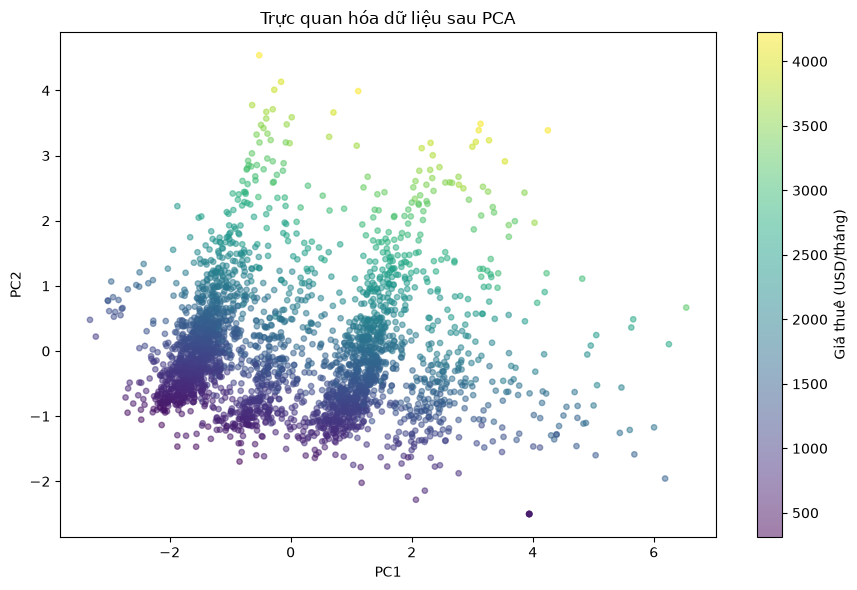

In [118]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

model_pca = PCA(n_components=2)

X_pca_2d = model_pca.fit_transform(X_pca)

print("Kích thước dữ liệu gốc:", X_pca.shape)
print("Kích thước sau PCA:", X_pca_2d.shape)

print("Tỷ lệ phương sai PC1:",
      round(model_pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Tỷ lệ phương sai PC2:",
      round(model_pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Tổng phương sai giữ lại:",
      round(model_pca.explained_variance_ratio_.sum() * 100, 2), "%")

df_pca_result = pd.DataFrame(
    X_pca_2d,
    columns=["PC1", "PC2"],
    index=df_pca.index
)

df_pca_result["price"] = df_pca["price"]

print("5 bản ghi sau giảm chiều:")
display(df_pca_result.head())

df_pca_plot = df_pca_result.sample(
    n=min(3000, len(df_pca_result)),
    random_state=42
)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df_pca_plot["PC1"],
    df_pca_plot["PC2"],
    c=df_pca_plot["price"],
    cmap="viridis",
    alpha=0.5,
    s=15
)

plt.colorbar(scatter, label="Giá thuê (USD/tháng)")

plt.title("Trực quan hóa dữ liệu sau PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()


**Nhận xét**
- Đã giảm dữ liệu từ (97388, 4) xuống (97388, 2), tức là số thuộc tính giảm từ 4 còn 2 trong khi số bản ghi được giữ nguyên.
- Hai thành phần chính PC1 và PC2 giải thích lần lượt 63,13% và 21,98% tổng phương sai, với tỷ lệ tích lũy là 85,11%. Kết quả này phù hợp với phương pháp tính trị riêng ở Cell 2.
- Trên biểu đồ Scatterplot, các điểm dữ liệu được phân bố theo hai trục PC1 và PC2. Phần lớn các điểm tập trung ở một số vùng, đồng thời vẫn có những điểm phân bố xa khu vực tập trung.
- Màu sắc biểu diễn giá thuê cho thấy các mức giá khác nhau có sự phân bố khác nhau trong không gian PCA. Những điểm có giá thuê thấp thường có màu tím hoặc xanh đậm, trong khi các điểm có giá thuê cao hơn có xu hướng xuất hiện với màu xanh lá và vàng.
- Tuy nhiên, các nhóm màu vẫn có sự chồng lấn, cho thấy hai thành phần chính chưa tạo ra sự phân tách hoàn toàn giữa những mức giá thuê khác nhau.

=> PCA đã giúp biểu diễn dữ liệu bốn thuộc tính trên không gian hai chiều và giữ lại phần lớn tổng phương sai. Biểu đồ hỗ trợ quan sát sự phân bố dữ liệu

**Kết luận chung**
Sau khi chuẩn hóa và tính toán ma trận hiệp phương sai, PC1 giải thích 63,13% và PC2 giải thích 21,98% tổng phương sai. Tổng cộng, hai thành phần giữ lại 85,11%, trong khi khoảng 14,89% phương sai không được giữ lại sau quá trình giảm chiều.

Kết quả tính toán cho tỷ lệ phương sai tương ứng, cho thấy quá trình giảm chiều được thực hiện nhất quán.

Nhìn chung, PCA giúp giảm số chiều và trực quan hóa dữ liệu hiệu quả hơn, đồng thời thể hiện sự phân bố của các căn hộ trong không gian hai chiều. Tuy nhiên, quá trình giảm chiều vẫn làm mất một phần phương sai và các thành phần mới khó giải thích trực tiếp so với thuộc tính ban đầu

## 11. Kết luận
### 11.1. Tổng hợp kết quả
Sau khi thực hiện phân tích bộ dữ liệu Apartment for Rent Classied, em đã áp dụng các phương pháp xử lý dữ liệu, thông kê, kiểm định giả thuyết và học máy để tìm hiểu một số đặc điểm của tin đăng cho thuê trong dataset.

Mốt số kết quả:
- **Tiền xử lý dữ liệu**: Dataset ban đầu có 99492 dòng và 22 cột. Sau khi loại bỏ các dòng trùng lặp, tin ngoài phạm vi và một số dữ liệu bất thường, không hợp lệ, dataset còn 99342 dòng để tiếp tục tiến hành phân tích
- **Thông kê và trực quan hóa**: Giá thue trung bình khoảng 1526,92 USD/tháng, trung vị là 1350 USD/tháng. Các tin tập trung chủ yếu ở nhóm căn hộ có 1-2 phòng ngủ. Phân phối giá thuê lệch phải và có một số giá trị ngoại lai lớn
- **Phân tích xác suất và kiểm định**: Phân phối Bino và Poission được sử dụng để tính xác suất cho các tình huống lựa chọn tin. Kiểm định T và Z Test cho thấy những khác biệt được keiemr tra có ý nghĩa thống kê ở mức 5%
- **Tương quan và hồi quy tuyến tính**: Diện tích và giá thuê có tương quan dương với hệ số P là 0,371. Mô hình hồi quy tuyến tính đơn đạt R^2 = 0,1686 mà MAE khoảng 509,42 USD/tháng, cho thấy khả năng dự đoán chỉ dựa trên diện tích còn hạn chế
- **HỌc máy**: Logistic Regression, Gaussian Naive Bayes và Decision Tree đạt Accuracy lần lượt là 63,54%, 63,23% và 63,70%. Decision Tree có kết quả cao nhất nhưng mức chênh lệch giữa các mô hình không lớn. K-Means phân dữ liệu thành 3 cụm căn hộ có đặc điểm khác nhau về giá thuê và diện tích. Thuật toán Apriori tìm được 246 tập mục phổ biến và 243 luật kết hợp giữa các tiện ích. Ngoài ra, PCA giảm dữ liệu từ 4 chiều xuống 2 chiều và giữ lại 85,11% tổng phương sai

Nhìn chung quá trình phân tích giúp hiểu rõ hơn về đặc điểm của bộ dữ liệu. Các kết quả cho thấy giá thuê có liên hệ với diện tích, số phòng và những đăc điểm khác của cnaw hộ, tuy nhiên mô hình vẫn có hạn chế.

### 11.2. Hạn chế
Mặc dù đã thực hiện các bước phân tích và áp dụng một số phương phá học máy, bài làm vẫn còn một số hạn chế
- **Chất lượng dữ liệu:**: Có thuộc tính có tỷ lệ dữ liệu thiếu khá lớn đặc biệt như (92,02%), pets_allowed (60,73%) và amenities (16,13%) ở dữ liệu gốc. Sau khi làm sạch, vẫn còn 9 thuộc tính có giá trị thiếu nên việc phân tích một số đặc điểm căn hộ còn bị giới hạn
- **Giá trị ngoại lai**: Giá thuê và diện tích có nhiều giá trị ngoại lai lớn, làm cho phân phối dữ liệu bị lệch phải. Bìa làm chưa xử lý toàn bộ các giá trị này do chưa có đủ cơ sở xác định là dữ liệu sai, do vậy thống kê và mô hình có kết quả bị ảnh hưởng
- **Khả năng dự đoán của mô hình**: Mô hình hồi quy tuyến tính R^2 = 0,1686 và các mô hình phân loại chỉ đạt khoảng 64%. Kết quả cho thấy khả năng dự đoán còn hạn chế khi sử dụng diện tích, số phòng ngủ hoặc số phòng tắm mà chưa xét đến các yếu tố khác như vị trí hoặc tiện ích
- **Giới hạn phương pháp**: k means sử dụng k = 3 dựa trên BĐ Elbow nhưng chauw thể khẳng định đây là số cụm tối ưu. Luật kết hợp chỉ phân tích những tin đăng có thông tin tiện ích và phụ thuộc và các ngưỡng Supoprt, Confidence đã chọn. PCA giữ lại  85,11% tổng phương sai nên vẫn có môt phần phương sai bị mất khi giảm chiều
- **Phạm vi dữ liệu**: Dữ liệu được đăng trên UCI vào năm 2019 và em chỉ tập trung và ocasc tin đăng cho thêu theo tháng do vậy kết quả chủ yếu phản ánh đặc điểm của bộ dữ liệu sử dụng, không đại diện cho đối tượng lớn hơn.

Nhìn chung bài làm đã giúp em thử ứng dụng các hàm và thuật toán vào phân tích, tuy vậy kết quả còn phụ thuộc vào chất lượng dữ liệu, các thuộc itnsh được lựa chọn và những giả định của từng phương pháp.